# CISC7204 Class E Team 01 — Data cleaning and analysis pipeline

**Project:** *Is Macau's transport keeping up with its visitors? A supply × demand match of public bus service against district-hour visitor load*

**Author of this notebook:** FONG CHIN WAI (Vivi), mc653748
**Role in the team (per Work Plan):** Developer · Analyst · Quality Reviewer (support) — owner of **M3** (data cleaning, integration, visualisation) and **Section G**
**Course:** CISC7204 Data Science and Data Visualization, 2026-1, class 001-E

---

## What this notebook is

This is the merged, single runnable pipeline for Team 01. It combines two earlier notebooks:

| Source | What was taken from it | What was dropped |
|---|---|---|
| `CISC7204-Assgn02-Pair08-ProposalVerification.ipynb` (Pair 08, Assgn 02) | the whole **data-acquisition and cleaning logic**: DSEC key-indicator parsing, MGTO district × hour panel construction, bus stop / route / timetable parsing, official supply series, Golden Week, and the supply–demand matching layers | its two Pair-08 figures (superseded by the Team 01 figure set) and its Pair-08 folder paths |
| `notebooks/cisc7204_proposal_figures_colour.ipynb` (Team 01 figures) | the **Figure 1–6 rendering block** (colour-blind-safe, print-size layout) | nothing |

Both were re-pointed at the Team 01 repository, so the raw folder is read once and every intermediate
file lands in `data_processed/` and every figure in `figures/`.

## Pipeline at a glance

| Stage | Content | Writes to |
|---|---|---|
| 1 | Raw-data inventory and usability screen | `data_processed/dataset_inventory.csv` |
| 2 | DSEC monthly arrivals (2008-01 → 2026-09) | `data_processed/demand_monthly_arrivals.csv` |
| 3 | MGTO district × hour headcount, year-to-date de-duplication, 45 months | `mgto_district_hour_master_…csv`, `demand_district_hour_panel_…csv` |
| 4 | Golden Week daily arrivals | `data_processed/demand_goldenweek_daily.csv` |
| 5 | Supply: stops, routes, 920 timetable windows → scheduled departures | `supply_stops.csv`, `supply_routes.csv`, `supply_departures_route_hour.csv`, `supply_stop_departures.csv` |
| 6 | Official supply series (fleet, stop stock, annual ridership, shuttle) | `supply_official_series.csv`, `supply_shuttle_quarterly.csv` |
| 7 | Integrated monthly / quarterly panels + data-quality report | `monthly_panel_…csv`, `quarterly_panel_…csv` |
| 8 | Matching layers: zone, hour-of-day, gateway, event, annual | `match_*.csv` |
| 9 | Figures 1–6 | `figures/fig1…fig6*.png` |
| 10 | SQLite warehouse + run manifest | `data_processed/macau_visitor_transport.sqlite` |

## Data-quality rules applied (M3 deliverable)

1. **Year-to-date trap.** Every MGTO monthly file is a *year-to-date* publication, so only the last file of
   each year is read (`202312`, `202412`, `202512`, `202609`). Reading all 45 files would count the same month
   up to twelve times.
2. **Balanced panel.** The district × hour grid must be exactly 24 hours × 24 districts = 576 rows per month;
   the notebook raises instead of silently continuing if a month is incomplete.
3. **Irregular file name, repaired not dropped.** The 2025-11 release is stored as
   `MacaoDistrictTourismData_2025011_en.xlsx`; the tag is parsed as year + last two digits, and every
   repaired name is printed so the correction is visible in the run log.
4. **Fixed analysis windows.** Core window 2023-01 → 2025-12 (36 months, pandemic excluded); the 2026
   matching window is 2026-01 → 2026-07 because July is the last month published for the hour-level
   indicator at the time of writing.
5. **Reported shares never change silently.** The zone and hourly matching layers are frozen to that 2026
   window so that re-running the notebook cannot drift away from the numbers printed in the proposal.

### Caveat carried over from the project brief

Every relationship reported here is **associational** — shares, gaps, correlations. No causal claim is made
about visitation.


---
## 0. Environment, paths and shared configuration

The repository root is detected from the notebook location (the notebook lives in `notebooks/`), so the
pipeline runs unchanged on any machine that has the repository.


In [1]:
import io
import glob
import json
import math
import os
import re
import sqlite3
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import textwrap

matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
matplotlib.rcParams["axes.unicode_minus"] = False
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)
try:                      # display() exists under ipykernel; keep a fallback for plain python
    display
except NameError:         # pragma: no cover
    def display(x):
        print(x.to_string() if hasattr(x, "to_string") else x)

# ----------------------------------------------------------------------------- paths
_cwd = os.path.abspath("")
REPO = os.path.dirname(_cwd) if os.path.basename(_cwd).lower() == "notebooks" else _cwd
if not os.path.isdir(os.path.join(REPO, "data_processed")):      # safety net
    raise RuntimeError(
        "data_processed/ not found next to this notebook: run it from the repository root, "
        "or from notebooks/ inside the repository, so the panels can be located"
    )

DATA   = os.path.join(REPO, "data")
GOV    = os.path.join(DATA, "gov_mo_datasets")
MGTO   = os.path.join(DATA, "mgtodataplus")
TS     = os.path.join(DATA, "dsec_timeseries")
GH     = os.path.join(DATA, "github_macau-bus-data", "macau-bus-data-master")
SHP    = os.path.join(DATA, "data.gov.mo_bus_route_shp", "ExportShapeFile20260919")
MPB    = os.path.join(DATA, "mopubbus")
DATASET = os.path.join(REPO, "Dataset")
PROC   = os.path.join(REPO, "data_processed")
FIGD   = os.path.join(REPO, "figures")
REPORTS = os.path.join(REPO, "reports")
for _d in (PROC, FIGD, REPORTS):
    os.makedirs(_d, exist_ok=True)

# ----------------------------------------------------------------------------- windows
WIN_START, WIN_END = "2023-01", "2025-12"        # 36-month core analysis window
PANEL_START, PANEL_END = "2023-01", "2026-09"    # full cleaned coverage
MATCH_YEAR, MATCH_LAST_MONTH = 2026, 7           # 2026 H1 + July = last hour-level month

# Okabe-Ito colour-blind-safe palette used by every figure
C = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00",
         purple="#CC79A7", sky="#56B4E9", yellow="#F0E442", grey="#8C8C8C")

# ----------------------------------------------------------------------------- districts
# The 24 MGTO statistical districts collapse into the 3 service zones used throughout.
ZONE_OF_CN = {
    "下環區": "Macau Peninsula", "中區": "Macau Peninsula", "南西灣及主教山區": "Macau Peninsula",
    "台山區": "Macau Peninsula", "外港及南灣湖新填海區": "Macau Peninsula", "新口岸區": "Macau Peninsula",
    "新橋區": "Macau Peninsula", "望廈及水塘區": "Macau Peninsula", "東望洋區(松山區)": "Macau Peninsula",
    "林茂塘區": "Macau Peninsula", "沙梨頭及大三巴區": "Macau Peninsula", "筷子基區": "Macau Peninsula",
    "荷蘭園區": "Macau Peninsula", "青洲區": "Macau Peninsula", "高士德及雅廉訪區": "Macau Peninsula",
    "黑沙環及祐漢區": "Macau Peninsula", "黑沙環新填海區": "Macau Peninsula",
    "北安及大潭山區": "Taipa & Cotai", "大學及北安灣區": "Taipa & Cotai", "氹仔中心區": "Taipa & Cotai",
    "氹仔舊城及馬場區": "Taipa & Cotai", "海洋及小潭山區": "Taipa & Cotai", "路氹填海區": "Taipa & Cotai",
    "路環區": "Coloane",
}
ZONE_ORDER = ["Macau Peninsula", "Taipa & Cotai", "Coloane"]


def esc(s):
    '''Readable form of a Chinese label when printing to a latin console.'''
    return str(s).encode("unicode_escape").decode()


def read_gov_xlsx(name, **kw):
    '''data.gov.mo ships each table as a zip that also holds readme.json.'''
    z = zipfile.ZipFile(os.path.join(GOV, name))
    inner = [n for n in z.namelist() if n.lower().endswith(".xlsx")][0]
    return pd.read_excel(io.BytesIO(z.read(inner)), **kw)


print("repository :", REPO)
print("raw data   :", os.path.isdir(DATA), "| processed ->", PROC)
print("figures    ->", FIGD)

repository : C:\Users\07viv\Desktop\CISC7204-Team01
raw data   : True | processed -> C:\Users\07viv\Desktop\CISC7204-Team01\data_processed
figures    -> C:\Users\07viv\Desktop\CISC7204-Team01\figures


---
## 1. Raw-data inventory and usability screen

Nothing below is simulated: each row is a file that exists in the repository. The screen records whether
the dataset can carry the demand × supply match or only provides context.


In [2]:
inv = []


def add(group, name, rel_path, note):
    p = os.path.join(REPO, rel_path.replace("/", os.sep))
    inv.append({"group": group, "dataset": name, "rel_path": rel_path,
                "size_kb": round(os.path.getsize(p) / 1024, 1) if os.path.exists(p) else None,
                "role_in_analysis": note})


add("Demand", "DSEC Key Indicator 27 - monthly visitor arrivals",
    r"data/dsec_timeseries/DSEC_KeyIndicator_27.json",
    "Total visitor arrivals per month, 2008-01..2026-08 (macro demand trend)")
add("Demand", "DSEC Key Indicator 127 - same-day visitor arrivals",
    r"data/dsec_timeseries/DSEC_KeyIndicator_127.json",
    "Same-day (non-overnight) arrivals per month - tourist type mix")
add("Demand", "DSEC Key Indicator 28 - arrivals year-on-year change",
    r"data/dsec_timeseries/DSEC_KeyIndicator_28.json",
    "Year-on-year % change - growth context for 2025/2026")
add("Demand", "MGTO Data+ district x hour visitor headcount (45 monthly files)",
    r"data/mgtodataplus/MacaoDistrictTourismData_202609_en.xlsx",
    "24 statistical districts x 24 hour slots, 2023-01..2026-09 - SPATIAL+TEMPORAL demand core")
add("Demand", "data.gov.mo tidy district x hour headcount",
    r"data/gov_mo_datasets/dst_visitor_01_stats.xlsx",
    "Same indicator in tidy long form - independent copy / cross-check of the MGTO parse")
add("Demand", "data.gov.mo district visits by origin",
    r"data/gov_mo_datasets/dst_visitor_02_stats.xlsx",
    "Person-time per district by origin - demand intensity by market")
add("Demand", "Golden-week daily arrivals",
    r"data/gov_mo_datasets/dst_goldenweekvisitor.xlsx",
    "Daily total during Spring Festival / 1 October Golden Weeks (2017-2026) - event demand")
add("Supply", "Bus stop master (stops.json)",
    r"data/github_macau-bus-data/macau-bus-data-master/stops.json",
    "586 bus stops with lat/lng - supply geography")
add("Supply", "Bus route master (routes.json)",
    r"data/github_macau-bus-data/macau-bus-data-master/routes.json",
    "91 routes with ordered stop lists - route geography and service intensity")
add("Supply", "Route timetable / headway windows",
    r"data/github_macau-bus-data/macau-bus-data-master/route-schedule",
    "920 route-direction-time windows with headway - SUPPLY CAPACITY core")
add("Supply", "DSAT bus network shapefiles + route sequence",
    r"data/data.gov.mo_bus_route_shp/ExportShapeFile20260919",
    "BUS_POLE / ROUTE_NETWORK shapes and BUS_ROUTE_SEQ.xls - official cross-check")
add("Supply", "Official monthly public bus fleet", r"data/gov_mo_datasets/Number_of_buses.xlsx",
    "Buses in service by month - capacity stock")
add("Supply", "Official monthly public bus stop count",
    r"data/gov_mo_datasets/Total_number_of public_bus_stops.xlsx",
    "Registered bus stops by month - network stock")
add("Supply", "Official annual public bus ridership",
    r"data/gov_mo_datasets/Number_of_public_bus_rides.xlsx",
    "Annual passenger trips - realised load")
add("Supply", "Hotel / casino shuttle ridership and departures",
    r"data/gov_mo_datasets/Hotel_casino_shuttle_bus_ridership_and_departure_frequency.xlsx",
    "Quarterly shuttle passenger trips + departures - parallel tourist transport channel")
add("Supply", "Land-port cross-border vehicle flow",
    r"data/gov_mo_datasets/陸路口岸跨境汽車流量(架次).xlsx",
    "Vehicles per land checkpoint per year - gateway pressure proxy")
add("Supply", "Checkpoint arrivals/departures by residency",
    r"data/gov_mo_datasets/各入境事務站出入境人數.xlsx",
    "Annual in/out flows per checkpoint and residency group")
add("Event", "MOPubBus trip records (figshare mirror)", r"data/mopubbus",
    "Trip-level passenger-flow level (0-5) for routes 3 and AP1, normal vs Grand Prix weeks")

inv_df = pd.DataFrame(inv)
inv_df.to_csv(os.path.join(PROC, "dataset_inventory.csv"), index=False, encoding="utf-8-sig")
display(inv_df[["group", "dataset", "size_kb", "role_in_analysis"]])

inv_df["exists"] = inv_df["rel_path"].map(lambda p: os.path.exists(os.path.join(REPO, p.replace("/", os.sep))))
print("inventory rows:", len(inv_df), "| present on disk:", int(inv_df.exists.sum()),
      "| missing:", int((~inv_df.exists).sum()))

mg_files = sorted(glob.glob(os.path.join(MGTO, "MacaoDistrictTourismData_*_en.xlsx")))


def month_tag(fname):
    '''Publication tag of an MGTO district-hour file.

    The files are named YYYYMM, but the 2025-11 release shipped as
    ``MacaoDistrictTourismData_2025011_en.xlsx`` (a stray zero). The tag is therefore read as
    year + last two digits, and every irregular file name is reported instead of being dropped.
    '''
    raw = re.search(r"_(\d{4,7})_", os.path.basename(fname)).group(1)
    return raw[:4] + raw[-2:], len(raw)


mg_tags, odd_names = [], []
for f in mg_files:
    tag, width = month_tag(f)
    mg_tags.append(tag)
    if width != 6:
        odd_names.append(f"{os.path.basename(f)} -> {tag}")
print("\nMGTO monthly district-hour files on disk :", len(mg_files))
print("tags                                     :", " ".join(mg_tags))
print("irregular file names repaired            :", odd_names if odd_names else "none")
assert len(set(mg_tags)) == len(mg_tags), "two MGTO files resolve to the same month tag"
print("raw / data folder size (MB)              :",
      round(sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(DATA) for f in fs) / 1048576, 1))

,group,dataset,size_kb,role_in_analysis
0,Demand,DSEC Key Indicator 27 - monthly visitor arrivals,77.7,"Total visitor arrivals per month, 2008-01..202..."
1,Demand,DSEC Key Indicator 127 - same-day visitor arri...,77.7,Same-day (non-overnight) arrivals per month - ...
2,Demand,DSEC Key Indicator 28 - arrivals year-on-year ...,79.7,Year-on-year % change - growth context for 202...
3,Demand,MGTO Data+ district x hour visitor headcount (...,580.1,"24 statistical districts x 24 hour slots, 2023..."
4,Demand,data.gov.mo tidy district x hour headcount,142.0,Same indicator in tidy long form - independent...
5,Demand,data.gov.mo district visits by origin,40.9,Person-time per district by origin - demand in...
6,Demand,Golden-week daily arrivals,21.7,Daily total during Spring Festival / 1 October...
7,Supply,Bus stop master (stops.json),104.3,586 bus stops with lat/lng - supply geography
8,Supply,Bus route master (routes.json),798.9,91 routes with ordered stop lists - route geog...
9,Supply,Route timetable / headway windows,12.0,920 route-direction-time windows with headway ...


inventory rows: 18 | present on disk: 18 | missing: 0

MGTO monthly district-hour files on disk : 45
tags                                     : 202301 202302 202303 202304 202305 202306 202307 202308 202309 202310 202311 202312 202401 202402 202403 202404 202405 202406 202407 202408 202409 202410 202411 202412 202511 202501 202502 202503 202504 202505 202506 202507 202508 202509 202510 202512 202601 202602 202603 202604 202605 202606 202607 202608 202609
irregular file names repaired            : ['MacaoDistrictTourismData_2025011_en.xlsx -> 202511']
raw / data folder size (MB)              : 28.1


---
## 2. Cleaning stage 1 — DSEC official monthly visitor arrivals

The DSEC key indicators are published as nested JSON; `walk()` collects every record that carries a
`ReferencePeriod` / `IndicatorValue` pair, the Portuguese month abbreviations are mapped to numbers, and the
three indicators (total, same-day, YoY) are joined on the month.


In [3]:
MONTHS = {"Jan.": 1, "Feb.": 2, "Mar.": 3, "Apr.": 4, "May": 5, "Jun.": 6,
          "Jul.": 7, "Aug.": 8, "Sep.": 9, "Oct.": 10, "Nov.": 11, "Dec.": 12}


def ki_series(fname):
    raw = json.load(io.open(os.path.join(TS, fname), encoding="utf-8"))
    recs = []

    def walk(o):
        if isinstance(o, dict):
            if "ReferencePeriod" in o and "IndicatorValue" in o:
                recs.append(o)
            for v in o.values():
                walk(v)
        elif isinstance(o, list):
            for v in o:
                walk(v)

    walk(raw)
    df = pd.DataFrame([{"period": r["ReferencePeriod"], "value": r["IndicatorValue"]} for r in recs])
    df["value"] = pd.to_numeric(df["value"].astype(str).str.replace(",", ""), errors="coerce")
    df["year"] = df["period"].str.extract(r"(\d{4})").astype(int)
    df["month"] = df["period"].str.split("/").str[0].map(MONTHS)
    df["date"] = pd.to_datetime(dict(year=df["year"], month=df["month"], day=1))
    return df[["date", "year", "month", "value"]].dropna().sort_values("date").reset_index(drop=True)


arr = ki_series("DSEC_KeyIndicator_27.json").rename(columns={"value": "arrivals"})
sameday = ki_series("DSEC_KeyIndicator_127.json").rename(columns={"value": "same_day_arrivals"})
yoy = ki_series("DSEC_KeyIndicator_28.json").rename(columns={"value": "arrivals_yoy_pct"})
dem = (arr.merge(sameday[["date", "same_day_arrivals"]], on="date", how="left")
          .merge(yoy[["date", "arrivals_yoy_pct"]], on="date", how="left"))
dem["same_day_share_pct"] = 100 * dem["same_day_arrivals"] / dem["arrivals"]

# The September 2026 figure was published after the JSON snapshot: append it from the repository export.
supp_path = os.path.join(DATASET, "DSEC_arrivals_2026_09_supplement.csv")
if os.path.exists(supp_path):
    supp = pd.read_csv(supp_path)[["year", "month", "arrivals"]]
    supp["date"] = pd.to_datetime(dict(year=supp["year"], month=supp["month"], day=1))
    dem = dem.merge(supp[["date", "arrivals"]], on="date", how="outer", suffixes=("", "_new"))
    dem["arrivals"] = dem["arrivals_new"].fillna(dem["arrivals"])
    dem = dem.drop(columns=["arrivals_new"]).dropna(subset=["arrivals"]).sort_values("date")
    dem["year"] = dem["date"].dt.year
    dem["month"] = dem["date"].dt.month
dem = dem.reset_index(drop=True)

dem.to_csv(os.path.join(PROC, "demand_monthly_arrivals.csv"), index=False, encoding="utf-8-sig")

print("monthly arrival series :", dem["date"].min().date(), "->", dem["date"].max().date(), "| n =", len(dem))
print("duplicated months      :", int(dem["date"].duplicated().sum()))
print("missing arrivals cells :", int(dem["arrivals"].isna().sum()))
print("2025 total arrivals    :", f"{int(dem[dem.year == 2025].arrivals.sum()):,}")
print("2026 Jan-Aug arrivals  :", f"{int(dem[(dem.year == 2026) & (dem.month <= 8)].arrivals.sum()):,}",
      "| YoY first 8 months:",
      round(100 * (dem[dem.year == 2026].head(8).arrivals.sum() / dem[dem.year == 2025].head(8).arrivals.sum() - 1), 1), "%")
print("latest month           :", dem.iloc[-1]["date"].date(), f"{int(dem.iloc[-1]['arrivals']):,}")
season = dem[dem.year.between(2015, 2019)].groupby("month")["arrivals"].mean()
season = (100 * season / season.mean()).round(1)
print("\nseasonality index (2015-2019 mean = 100):")
print(season.to_string())

monthly arrival series : 2008-01-01 -> 2026-09-01 | n = 225
duplicated months      : 0
missing arrivals cells : 0
2025 total arrivals    : 40,069,360
2026 Jan-Aug arrivals  : 28,964,737 | YoY first 8 months: 7.7 %
latest month           : 2026-09-01 3,216,535

seasonality index (2015-2019 mean = 100):
month
1      98.8
2     102.2
3      93.9
4     100.2
5      97.0
6      89.8
7     105.7
8     111.9
9      89.6
10    103.1
11    100.5
12    107.3


---
## 3. Cleaning stage 2 — MGTO district × hour visitor headcount (2023-01 → 2026-09)

### 3.1 The year-to-date de-duplication rule

Every monthly MGTO file contains **all months of its year up to the publication month**. Reading all 45 files
would multiply-count January up to twelve times. The pipeline therefore keeps only the last file of each year
and then asserts the result is a **balanced 24 districts × 24 hours grid**.


In [4]:
ytd = {}
for f in mg_files:
    tag = month_tag(f)[0]
    ytd.setdefault(tag[:4], []).append(tag)
YTD_FILES = [f"MacaoDistrictTourismData_{max(t)}_en.xlsx" for y, t in sorted(ytd.items())]
print("files per year on disk :", {y: len(t) for y, t in sorted(ytd.items())})
print("year-to-date files kept:", YTD_FILES)

frames = []
for f in YTD_FILES:
    raw = pd.read_excel(os.path.join(MGTO, f), sheet_name="1", header=None)
    raw = raw[pd.to_numeric(raw[0], errors="coerce").notna()].copy()   # drop the two header rows
    part = pd.DataFrame({
        "year": pd.to_numeric(raw[0]).astype(int),
        "month": pd.to_numeric(raw[1]).astype(int),
        "period": raw[2].astype(str).str.strip(),
        "district_cn": raw[3].astype(str).str.strip(),
        "district_en": raw[5].astype(str).str.strip(),
        "headcount": pd.to_numeric(raw[6], errors="coerce"),
    })
    frames.append(part)
    print(f"  {f:44s} -> {len(part):6d} rows | months {min(part.month)}-{max(part.month)}")

panel = pd.concat(frames, ignore_index=True)

# --- quality gate 1: no duplicate (year, month, district, period) keys -----------------
dups = panel.duplicated(subset=["year", "month", "district_cn", "period"]).sum()
assert dups == 0, f"{dups} duplicated district-hour keys - the year-to-date rule is broken"

# --- quality gate 2: missing headcount -------------------------------------------------
n_missing = int(panel["headcount"].isna().sum())
panel = panel.dropna(subset=["headcount"]).reset_index(drop=True)

# --- quality gate 3: balanced 576-row months -------------------------------------------
per_month = panel.groupby(["year", "month"]).size()
assert per_month.nunique() == 1 and int(per_month.iloc[0]) == 576, "district-hour grid is not balanced"
assert len(per_month) == 45, f"expected 45 months, found {len(per_month)}"

panel["hour"] = panel["period"].str.split(":").str[0].astype(int)
panel["zone"] = panel["district_cn"].map(ZONE_OF_CN)
unmapped = sorted(panel.loc[panel.zone.isna(), "district_cn"].unique())
assert not unmapped, f"unmapped districts: {unmapped}"

print("\ndistrict-hour panel :", panel.shape, "| months:", len(per_month),
      "| districts:", panel.district_cn.nunique(), "| hours:", panel.hour.nunique())
print("dropped empty cells :", n_missing, "| duplicated keys:", int(dups))
print("negative values     :", int((panel.headcount < 0).sum()))
print("coverage            :", f"{PANEL_START} .. {panel.assign(m=panel.year.astype(str)+'-'+panel.month.astype(str).str.zfill(2)).m.max()}")

dist_lookup = (panel.groupby(["district_cn", "district_en", "zone"]).size()
                    .reset_index()[["district_cn", "district_en", "zone"]])
display(dist_lookup)

files per year on disk : {'2023': 12, '2024': 12, '2025': 12, '2026': 9}
year-to-date files kept: ['MacaoDistrictTourismData_202312_en.xlsx', 'MacaoDistrictTourismData_202412_en.xlsx', 'MacaoDistrictTourismData_202512_en.xlsx', 'MacaoDistrictTourismData_202609_en.xlsx']


  MacaoDistrictTourismData_202312_en.xlsx      ->   6912 rows | months 1-12


  MacaoDistrictTourismData_202412_en.xlsx      ->   6912 rows | months 1-12


  MacaoDistrictTourismData_202512_en.xlsx      ->   6912 rows | months 1-12


  MacaoDistrictTourismData_202609_en.xlsx      ->   5184 rows | months 1-9

district-hour panel : (25920, 8) | months: 45 | districts: 24 | hours: 24
dropped empty cells : 0 | duplicated keys: 0
negative values     : 0
coverage            : 2023-01 .. 2026-09


,district_cn,district_en,zone
0,下環區,Barra/Manduco,Macau Peninsula
1,中區,Baixa de Macau,Macau Peninsula
2,北安及大潭山區,Pac On & Taipa Grande,Taipa & Cotai
3,南西灣及主教山區,Praia Grande & Penha,Macau Peninsula
4,台山區,Tamagnini Barbosa,Macau Peninsula
5,外港及南灣湖新填海區,Novos Aterros do Porto Exterior & Aterros da B...,Macau Peninsula
6,大學及北安灣區,Universidade & Baía de Pac On,Taipa & Cotai
7,新口岸區,Zona de Aterros do Porto Exterior,Macau Peninsula
8,新橋區,Barca,Macau Peninsula
9,望廈及水塘區,Móng Há & Reservatório,Macau Peninsula


### 3.2 The cleaned panel and the 2026 matching snapshot

`p26` is the 2026 slice used by every matching layer (2026-01 → 2026-07, the last month that carries the
hour-level indicator). Freezing it here is what keeps the proposal numbers reproducible.


In [5]:
p26 = panel[(panel.year == MATCH_YEAR) & (panel.month <= MATCH_LAST_MONTH)].copy()
tot26 = p26.headcount.sum()

print("2026 matching snapshot : months", f"1-{MATCH_LAST_MONTH}",
      "| total hourly headcount", f"{int(tot26):,}")
print("rows:", len(p26), "| districts:", p26.district_cn.nunique(), "| hours:", p26.hour.nunique())

bydist = p26.groupby(["district_en", "zone"])["headcount"].sum().sort_values(ascending=False)
share = (100 * bydist / tot26).round(2)
print("\nTop 10 districts by visitor headcount (2026 Jan-Jul):")
print(pd.DataFrame({"headcount": bydist.head(10).values, "share_pct": share.head(10).values},
                   index=[i[0] for i in bydist.head(10).index]).to_string())

zoneshare = p26.groupby("zone")["headcount"].sum()
zone_share_demand = (100 * zoneshare / tot26).round(2).reindex(ZONE_ORDER)
print("\nZone shares of visitor headcount:")
print(zone_share_demand.to_string())

hour_profile = p26.groupby("hour")["headcount"].sum()
hour_share_demand = (100 * hour_profile / hour_profile.sum()).round(3)
print("\nHour-of-day demand share (% of daily visitor hours), peak hour:",
      int(hour_share_demand.idxmax()), "h =", hour_share_demand.max(), "%")
print(hour_share_demand.to_string())

# --- exports --------------------------------------------------------------------------
master_cols = ["year", "month", "period", "district_cn", "district_en", "headcount", "hour", "zone"]
panel[master_cols].to_csv(os.path.join(PROC, "mgto_district_hour_master_2023_01_2026_09.csv"),
                          index=False, encoding="utf-8-sig")
panel[master_cols].to_csv(os.path.join(PROC, "demand_district_hour_panel_2023_2026.csv"),
                          index=False, encoding="utf-8-sig")
p26[master_cols].to_csv(os.path.join(PROC, "demand_district_hour_2026.csv"), index=False, encoding="utf-8-sig")
print("\nwritten: mgto_district_hour_master_2023_01_2026_09.csv (",
      len(panel), "rows ), demand_district_hour_panel_2023_2026.csv, demand_district_hour_2026.csv")

2026 matching snapshot : months 1-7 | total hourly headcount 24,214,416
rows: 4032 | districts: 24 | hours: 24

Top 10 districts by visitor headcount (2026 Jan-Jul):
                                                                   headcount  share_pct
COTAI Reclamation Area                                              10811489      44.65
Novos Aterros do Porto Exterior & Aterros da Baía da Praia Grande    2272657       9.39
Zona de Aterros do Porto Exterior                                    2144720       8.86
Baixa de Macau                                                       1677496       6.93
Cidade & Hipódromo da Taipa                                           958665       3.96
Pac On & Taipa Grande                                                 883060       3.65
Areia Preta & Iao Hon                                                 802505       3.31
Baixa da Taipa                                                        741308       3.06
Patane & São Paulo                        


written: mgto_district_hour_master_2023_01_2026_09.csv ( 25920 rows ), demand_district_hour_panel_2023_2026.csv, demand_district_hour_2026.csv


---
## 4. Cleaning stage 3 — Golden Week daily arrivals (event view)

Daily arrivals exist only for the Spring Festival and 1 October Golden Weeks. Each day is expressed relative to
the average day of its own publication month, which makes the 2017–2026 weeks comparable despite the trend.


In [6]:
gw = read_gov_xlsx("dst_goldenweekvisitor.xlsx")
gw = gw.rename(columns={"golden_week_en": "gw", "visitor_arrivals_en": "series", "visitor": "arrivals"})
gw = gw[["year", "gw", "date", "series", "arrivals"]].dropna(subset=["arrivals"])
gw = gw[gw.series.astype(str).str.contains("Total")]
gw["date"] = pd.to_datetime(gw["date"])
gw["gw_label"] = gw["gw"].astype(str) + " " + gw["year"].astype(str)
gw["day_index"] = gw.groupby("gw_label").cumcount() + 1
gw = gw.sort_values("date").reset_index(drop=True)

dix = dem.set_index("date")
baseline = dix["arrivals"] / dix.index.days_in_month
gw["month_baseline_daily"] = [baseline.get(pd.Timestamp(d.year, d.month, 1), np.nan) for d in gw["date"]]
gw["ratio_vs_month_avg"] = gw["arrivals"] / gw["month_baseline_daily"]
gw.to_csv(os.path.join(PROC, "demand_goldenweek_daily.csv"), index=False, encoding="utf-8-sig")

recent = gw[gw.year >= 2023].groupby("gw_label").agg(
    days=("arrivals", "size"), gw_daily=("arrivals", "mean"), ratio=("ratio_vs_month_avg", "mean"))
print("Golden Week daily arrivals vs same-month average (2017-2026 file):")
print(recent.round(2).to_string())
print("\npeak single day:", gw.loc[gw.arrivals.idxmax(), ["date", "arrivals"]].to_dict())

Golden Week daily arrivals vs same-month average (2017-2026 file):
                                  days   gw_daily  ratio
gw_label                                                
1st October Golden Week 2023         8  115410.88   1.35
1st October Golden Week 2024         7  133265.71   1.32
1st October Golden Week 2025         8  141377.88   1.26
Spring Festival Golden Week 2023     7   64328.29   1.43
Spring Festival Golden Week 2024     8  169588.12   1.49
Spring Festival Golden Week 2025     8  163700.12   1.43
Spring Festival Golden Week 2026     9  172708.11   1.16

peak single day: {'date': Timestamp('2026-02-19 00:00:00'), 'arrivals': 227917}


---
## 5. Cleaning stage 4 — supply side: stops, routes, timetables

### 5.1 Stop geography and macro-zone assignment

Zones are derived from the stop coordinates themselves: the largest latitude gap in the 586-stop point cloud
separates the Peninsula from the islands, and a Coloane latitude band plus place names separates Taipa/Cotai
from Coloane (the UM campus sits at Coloane latitudes but belongs to Taipa & Cotai).


In [7]:
stops = pd.DataFrame(json.load(io.open(os.path.join(GH, "stops.json"), encoding="utf-8")))
routes = json.load(io.open(os.path.join(GH, "routes.json"), encoding="utf-8"))
print("stops:", stops.shape, "| routes:", len(routes))

lat = np.sort(stops["lat"].values)
gaps = np.diff(lat)
order = np.argsort(gaps)[::-1]
PEN_THR = round(lat[order[0]] + gaps[order[0]] / 2, 4)
COL_THR = 22.124
print("latitude threshold Peninsula >= %.4f | Coloane < %.4f (+ Coloane place names)" % (PEN_THR, COL_THR))

COLOANE_NAME_RE = re.compile("|".join(["石排灣", "九澳", "和諧", "樂居", "業興", "居雅", "金峰", "鷺環", "聯生",
                                       "黑沙", "竹灣", "路環市區", "路環街市", "路環監獄", "路環居民", "路環警察",
                                       "路環小型", "聖路濟亞", "蝴蝶谷", "安順"]))


def zone_of(v, name=""):
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return "unclassified"
    if v >= PEN_THR:
        return "Macau Peninsula"
    if v < COL_THR or COLOANE_NAME_RE.search(str(name or "")):
        return "Coloane"
    return "Taipa & Cotai"


stops["zone"] = [zone_of(a, b) for a, b in zip(stops["lat"], stops["nameCht"])]
print("stops per macro-zone:", stops["zone"].value_counts().to_dict())

rows = []
for r in routes:
    # routes.json repeats the route code as the direction "code", so the positional index is used
    # as the direction id - the numbering the route-schedule files also use.
    for di, d in enumerate(r.get("directions", [])):
        for s in d.get("stops", []):
            rows.append({"route": r.get("code"), "dir": di, "stop_code": s.get("code"),
                         "stop_name": s.get("nameCht"), "lat": s.get("lat"), "lng": s.get("lng")})
svc = pd.DataFrame(rows)
svc["zone"] = [zone_of(a, b) for a, b in zip(svc["lat"], svc["stop_name"])]
svc["route_dir"] = svc["route"].astype(str) + "_" + svc["dir"].astype(str)
print("route-stop service records:", svc.shape)

intensity = svc.groupby("stop_code").agg(n_routes=("route", "nunique"),
                                         n_route_dir=("route_dir", "nunique"),
                                         n_records=("dir", "size")).reset_index()
stops = stops.merge(intensity, left_on="code", right_on="stop_code", how="left").fillna({"n_routes": 0})
stops["n_routes"] = stops["n_routes"].astype(int)


def hav_matrix(a, b):
    lat1 = np.radians(a[:, 0])[:, None]; lon1 = np.radians(a[:, 1])[:, None]
    lat2 = np.radians(b[:, 0])[None, :]; lon2 = np.radians(b[:, 1])[None, :]
    d = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371000 * 2 * np.arcsin(np.sqrt(np.clip(d, 0, 1)))


Dm = hav_matrix(stops[["lat", "lng"]].values, stops[["lat", "lng"]].values)
np.fill_diagonal(Dm, np.inf)
stops["nn_dist_m"] = Dm.min(axis=1)

sup_zone = stops.groupby("zone").agg(stops=("code", "size"), mean_routes_per_stop=("n_routes", "mean"),
                                     median_nn_m=("nn_dist_m", "median")).round(2)
sup_zone["stop_share_pct"] = (100 * sup_zone.stops / sup_zone.stops.sum()).round(2)
print("\nstop supply by macro-zone:")
print(sup_zone.to_string())
print("\nbusiest interchange stops:")
print(stops.sort_values("n_routes", ascending=False).head(8)[["nameCht", "namePor", "zone", "n_routes"]]
          .to_string(index=False))
stops.to_csv(os.path.join(PROC, "supply_stops.csv"), index=False, encoding="utf-8-sig")

stops: (586, 6) | routes: 91
latitude threshold Peninsula >= 22.1728 | Coloane < 22.1240 (+ Coloane place names)
stops per macro-zone: {'Macau Peninsula': 351, 'Taipa & Cotai': 179, 'Coloane': 56}
route-stop service records: (2843, 8)

stop supply by macro-zone:
                 stops  mean_routes_per_stop  median_nn_m  stop_share_pct
zone                                                                     
Coloane             56                  3.36        27.80            9.56
Macau Peninsula    351                  4.61        36.72           59.90
Taipa & Cotai      179                  5.17        36.54           30.55

busiest interchange stops:
  nameCht                          namePor            zone  n_routes
連貫公路/新濠影匯      EST. DO ISTMO / STUDIO CITY   Taipa & Cotai        16
  史伯泰/盧廉若        ESPARTEIRO / LOU LIM IEOK   Taipa & Cotai        16
   蘇利安圓形地             ROTUNDA LEONEL SOUSA   Taipa & Cotai        15
  史伯泰/麗景灣             ESPARTEIRO / REGENCY   Taipa & Cotai     

In [8]:
rows = []
for r in routes:
    zc, nstops = {}, 0
    for d in r.get("directions", []):
        for s in d.get("stops", []):
            if s.get("lat") is None:
                continue
            z = zone_of(s["lat"], s.get("nameCht"))
            zc[z] = zc.get(z, 0) + 1
            nstops += 1
    zset = {k for k, v in zc.items() if v > 0}
    rows.append({"route": r.get("code"), "nameCht": r.get("nameCht"), "type": r.get("type"),
                 "n_directions": len(r.get("directions", [])), "n_stop_records": nstops,
                 "zones_served": " + ".join(sorted(zset)),
                 "cross_bridge": ("Macau Peninsula" in zset) and ("Taipa & Cotai" in zset or "Coloane" in zset),
                 "reaches_coloane": "Coloane" in zset})
rdf = pd.DataFrame(rows)
rdf.to_csv(os.path.join(PROC, "supply_routes.csv"), index=False, encoding="utf-8-sig")
print("routes:", len(rdf), "| bridge-crossing:", int(rdf.cross_bridge.sum()),
      "| peninsula-only:",
      int(((~rdf.cross_bridge) & rdf.zones_served.str.contains("Peninsula")).sum()),
      "| islands-only:",
      int((~rdf.cross_bridge).sum() - ((~rdf.cross_bridge) & rdf.zones_served.str.contains("Peninsula")).sum()))
for z in ZONE_ORDER:
    sel = rdf[rdf.zones_served.str.contains(z)]
    print(f"  routes calling at {z:16s}: {len(sel):3d}  (bridge-crossing: {int(sel.cross_bridge.sum())})")

routes: 91 | bridge-crossing: 39 | peninsula-only: 43 | islands-only: 9
  routes calling at Macau Peninsula :  82  (bridge-crossing: 39)
  routes calling at Taipa & Cotai   :  48  (bridge-crossing: 39)
  routes calling at Coloane         :  17  (bridge-crossing: 16)


### 5.2 Scheduled service per hour from the 920 timetable windows

Headway ranges (e.g. `4-8`) become their midpoint, windows crossing midnight are extended past 24 h, and every
window is spread over the hours it covers. The output is departures per route-direction-hour for weekdays,
weekends and holidays — the supply measure used by the matching layers.


In [9]:
SCHED = os.path.join(GH, "route-schedule")


def hhmm_to_h(s):
    h, m = [int(x) for x in str(s).strip().split(":")[:2]]
    return h + m / 60.0


def headway_mid(s):
    s = str(s).strip()
    if "-" in s:
        a, b = s.split("-")[:2]
        return (float(a) + float(b)) / 2.0
    return float(s)


sched_rows = []
for fp in sorted(glob.glob(os.path.join(SCHED, "*"))):
    if os.path.isdir(fp):
        continue
    route = os.path.basename(fp)
    for line in io.open(fp, encoding="utf-8", errors="replace").read().splitlines():
        parts = [p.strip() for p in line.split(",")]
        if len(parts) < 6:
            continue
        try:
            _, direction, start, end, freq, daytype = parts[:6]
            h0, h1 = hhmm_to_h(start), hhmm_to_h(end)
            if h1 <= h0:
                h1 += 24
            hw = headway_mid(freq)
            if hw <= 0:
                continue
        except Exception:
            continue
        sched_rows.append({"route": route, "direction": int(direction), "start_h": h0, "end_h": h1,
                           "span_h": h1 - h0, "headway_min": hw, "daytype": daytype.lower(),
                           "trips_window": (h1 - h0) * 60.0 / hw})
sched = pd.DataFrame(sched_rows)
print("timetable windows parsed:", sched.shape, "| routes covered:", sched.route.nunique(),
      "| daytypes:", sorted(sched.daytype.unique()))

hours = np.arange(24)
hourly_dep = []
for (route, direction, daytype), g in sched.groupby(["route", "direction", "daytype"]):
    arr_h = np.zeros(24)
    for _, w in g.iterrows():
        for k in range(24):                          # bucket k covers the hour-of-day [k, k+1)
            ov = 0.0
            for lo in (k, k + 24):                   # windows crossing midnight end past 24 h
                ov += max(0.0, min(w.end_h, lo + 1.0) - max(w.start_h, lo))
            if ov > 0:
                arr_h[k] += ov * 60.0 / w.headway_min
    for k in range(24):
        hourly_dep.append({"route": route, "direction": direction, "daytype": daytype,
                           "hour": k, "departures": arr_h[k]})
dep = pd.DataFrame(hourly_dep)
dep = dep.merge(rdf[["route", "cross_bridge", "zones_served", "reaches_coloane"]], on="route", how="left")
dep.to_csv(os.path.join(PROC, "supply_departures_route_hour.csv"), index=False, encoding="utf-8-sig")

route_day = dep.groupby(["route", "daytype"])["departures"].sum().unstack().round(1)
print("\nnetwork scheduled departures per day (all routes, both directions):")
print(route_day.sum().round(0).to_string())
print("cross-bridge share of weekday departures:",
      round(100 * route_day.loc[rdf.set_index("route").cross_bridge, "weekdays"].sum() / route_day["weekdays"].sum(), 1), "%")

timetable windows parsed: (920, 8) | routes covered: 91 | daytypes: ['holidays', 'weekdays', 'weekends']



network scheduled departures per day (all routes, both directions):
daytype
holidays    8097.0
weekdays    9583.0
weekends    9142.0
cross-bridge share of weekday departures: 40.6 %


### 5.3 Official supply series — fleet, stop stock, annual ridership, shuttle channel

In [10]:
def gov_table(name, cols):
    '''data.gov.mo sheets carry a blank spacer row, then the header row, then data.'''
    d = read_gov_xlsx(name, header=None).iloc[2:].copy()
    d.columns = cols[:d.shape[1]]
    return d.reset_index(drop=True)


fleet = gov_table("Number_of_buses.xlsx", ["year", "item", "subitem", "amount", "month"])
stopc = gov_table("Total_number_of public_bus_stops.xlsx", ["year", "item", "subitem", "amount", "month"])
rides = gov_table("Number_of_public_bus_rides.xlsx", ["item", "year", "amount"])
shuttle = gov_table("Hotel_casino_shuttle_bus_ridership_and_departure_frequency.xlsx",
                    ["item", "year", "quarter", "amount"])
for d in (fleet, stopc, rides, shuttle):
    d["amount"] = pd.to_numeric(d["amount"], errors="coerce")
for d in (fleet, stopc):
    d["year"] = d["year"].astype(int)
    d["month"] = d["month"].astype(int)
fleet["date"] = pd.to_datetime(dict(year=fleet["year"], month=fleet["month"], day=1))
stopc["date"] = pd.to_datetime(dict(year=stopc["year"], month=stopc["month"], day=1))
rides["year"] = rides["year"].astype(int)

print("bus fleet (monthly) :", int(fleet["amount"].iloc[0]), "->", int(fleet["amount"].iloc[-1]),
      "| period", fleet["date"].min().date(), fleet["date"].max().date(), "| n =", len(fleet))
print("bus stops (monthly) :", int(stopc["amount"].iloc[0]), "->", int(stopc["amount"].iloc[-1]),
      "| period", stopc["date"].min().date(), stopc["date"].max().date(), "| n =", len(stopc))
print("\nannual public bus passenger trips:")
print(rides[["year", "amount"]].to_string(index=False))

ITEM_MAP = {"乘搭人次(人)": "ridership", "發車班次(班)": "departures"}
shuttle["item"] = shuttle["item"].map(lambda x: ITEM_MAP.get(str(x).strip(), str(x).strip()))
sh = shuttle.pivot_table(index=["year", "quarter"], columns="item", values="amount").reset_index()
sh["period"] = sh["year"].astype(str) + sh["quarter"]
print("\nhotel / casino shuttle (quarterly, last 8):")
print(sh.tail(8).to_string(index=False))
print("\nshuttle Q1 2026 ridership vs Q1 2020:",
      round(100 * (sh.loc[(sh.year == 2026) & (sh.quarter == "Q1"), "ridership"].values[0]
                   / sh.loc[(sh.year == 2020) & (sh.quarter == "Q1"), "ridership"].values[0] - 1), 1), "%")

off = pd.concat([
    fleet.assign(indicator="public buses in service",
                 period=fleet["date"].dt.strftime("%Y-%m"))[["indicator", "period", "amount"]],
    stopc.assign(indicator="public bus stops",
                 period=stopc["date"].dt.strftime("%Y-%m"))[["indicator", "period", "amount"]],
    rides.assign(indicator="annual public bus passenger trips",
                 period=rides["year"].astype(str))[["indicator", "period", "amount"]],
], ignore_index=True)
off.to_csv(os.path.join(PROC, "supply_official_series.csv"), index=False, encoding="utf-8-sig")
sh.to_csv(os.path.join(PROC, "supply_shuttle_quarterly.csv"), index=False, encoding="utf-8-sig")
print("\nwritten: supply_official_series.csv (", len(off), "rows ), supply_shuttle_quarterly.csv")

bus fleet (monthly) : 915 -> 964 | period 2019-01-01 2026-03-01 | n = 87
bus stops (monthly) : 413 -> 450 | period 2019-01-01 2026-03-01 | n = 87

annual public bus passenger trips:
 year    amount
 2018 214709065
 2019 228941399
 2020 166422166
 2021 193238314
 2022 168494190
 2023 214206088
 2024 227386737
 2025 231497093

hotel / casino shuttle (quarterly, last 8):
 year quarter  departures  ridership period
 2024      Q2    752243.0 12188921.0 2024Q2
 2024      Q3    787757.0 14096905.0 2024Q3
 2024      Q4    826842.0 13875625.0 2024Q4
 2025      Q1    755314.0 14663282.0 2025Q1
 2025      Q2    747430.0 14194667.0 2025Q2
 2025      Q3    743610.0 15305425.0 2025Q3
 2025      Q4    742443.0 15344449.0 2025Q4
 2026      Q1    757497.0 16453272.0 2026Q1

shuttle Q1 2026 ridership vs Q1 2020: 242.1 %

written: supply_official_series.csv ( 182 rows ), supply_shuttle_quarterly.csv


---
## 6. Integration stage — monthly and quarterly panels

The district-hour table is aggregated to a month, then joined with the DSEC arrival series, the hotel survey
(occupancy, guests, room stock) and the DSAT monthly bus statistics. The result is the one table the rest of
the team works from: one row per month, 45 rows, 2023-01 → 2026-09.

*Written identically to `scripts/build_panels.py`, so the notebook and the script cannot drift apart.*


In [11]:
# ---------------------------------------------------------------- monthly panel
_arr = dem[["year", "month", "arrivals"]].rename(columns={"arrivals": "visitor_arrivals"})
_supp_path = os.path.join(DATASET, "DSEC_arrivals_2026_09_supplement.csv")
if os.path.exists(_supp_path):
    _supp = pd.read_csv(_supp_path).rename(columns={"arrivals": "visitor_arrivals"})
    _arr = pd.concat([_arr, _supp], ignore_index=True).drop_duplicates(subset=["year", "month"], keep="last")

occ = pd.read_csv(os.path.join(DATASET, "Hotel_occ_total.csv"))
occ = occ[occ["Hotel Establishments"].astype(str).str.strip() == "Total"]
occ = occ[occ["Month"].notna()]
occ = pd.DataFrame({"year": occ["Year"].astype(int), "month": occ["Month"].astype(int),
                    "hotel_occ_pct": pd.to_numeric(occ["Occupancy rate"], errors="coerce")})

hr = pd.read_csv(os.path.join(DATASET, "DSEC_hotel_guests_rooms_2023_01_2026_09.csv"))
hr["year"] = hr["month"].str.slice(0, 4).astype(int)
hr["month"] = hr["month"].str.slice(5, 7).astype(int)
hr = hr.rename(columns={"guests": "hotel_guests", "rooms": "hotel_rooms"})

bus = pd.read_csv(os.path.join(REPO, "Monthly_Bus_Database", "bus_monthly_2020_2026.csv"))
bus = pd.DataFrame({"year": bus["year"].astype(int), "month": bus["month_no"].astype(int),
                    "bus_daily_avg_trips_wan": bus["daily_avg_trips_wan"],
                    "bus_monthly_trips": bus["monthly_trips_est"],
                    "buses_in_service": bus["buses_in_service"]})

dist_month = (panel.groupby(["year", "month"])["headcount"].sum().reset_index()
                   .rename(columns={"headcount": "mgto_district_headcount"}))

monthly = (_arr.merge(occ, on=["year", "month"], how="left")
               .merge(hr, on=["year", "month"], how="left")
               .merge(bus, on=["year", "month"], how="left")
               .merge(dist_month, on=["year", "month"], how="left"))
monthly["month"] = pd.to_datetime(dict(year=monthly["year"], month=monthly["month"], day=1)).dt.strftime("%Y-%m")
monthly["month_no"] = pd.to_datetime(monthly["month"]).dt.month
monthly["quarter"] = monthly["year"].astype(str) + "Q" + pd.to_datetime(monthly["month"]).dt.quarter.astype(str)
monthly["bus_trips_per_arrival"] = (monthly["bus_monthly_trips"] / monthly["visitor_arrivals"]).round(4)
monthly = monthly[["month", "year", "month_no", "quarter", "visitor_arrivals", "hotel_occ_pct", "hotel_guests",
                   "hotel_rooms", "bus_daily_avg_trips_wan", "bus_monthly_trips", "buses_in_service",
                   "mgto_district_headcount", "bus_trips_per_arrival"]].sort_values(["year", "month_no"]).reset_index(drop=True)
monthly = monthly[(monthly["month"] >= PANEL_START) & (monthly["month"] <= PANEL_END)].reset_index(drop=True)
assert len(monthly) == 45, f"monthly panel has {len(monthly)} rows, expected 45"

# ---------------------------------------------------------------- quarterly roll-up
g = monthly.groupby("quarter", sort=True)
quarterly = pd.DataFrame({
    "months_in_data": g.size(),
    "visitor_arrivals_sum": g["visitor_arrivals"].sum(),
    "hotel_occ_avg_pct": g["hotel_occ_pct"].mean().round(1),
    "hotel_guests_sum": g["hotel_guests"].sum(),
    "hotel_rooms_avg": g["hotel_rooms"].mean(),
    "bus_daily_avg_trips_wan_mean": g["bus_daily_avg_trips_wan"].mean().round(2),
    "bus_monthly_trips_sum": g["bus_monthly_trips"].sum(),
    "buses_in_service_max": g["buses_in_service"].max(),
    "mgto_district_headcount_sum": g["mgto_district_headcount"].sum(),
}).reset_index()
for _c in ["visitor_arrivals_sum", "hotel_guests_sum", "bus_monthly_trips_sum", "mgto_district_headcount_sum"]:
    quarterly[_c] = quarterly[_c].astype("Int64")
quarterly["hotel_rooms_avg"] = np.trunc(quarterly["hotel_rooms_avg"].to_numpy()).astype("int64")
quarterly["months_in_data"] = quarterly["months_in_data"].astype(int)
quarterly["buses_in_service_max"] = quarterly["buses_in_service_max"].astype(float)
quarterly["bus_trips_per_arrival"] = (quarterly["bus_monthly_trips_sum"] / quarterly["visitor_arrivals_sum"]).round(4)
quarterly["district_hits_per_arrival"] = (quarterly["mgto_district_headcount_sum"] / quarterly["visitor_arrivals_sum"]).round(4)

monthly.to_csv(os.path.join(PROC, "monthly_panel_2023_01_2026_09.csv"), index=False, encoding="utf-8-sig")
quarterly.to_csv(os.path.join(PROC, "quarterly_panel_2023Q1_2026Q3.csv"), index=False, encoding="utf-8-sig")

print("monthly panel   :", monthly.shape, "|", monthly["month"].min(), "..", monthly["month"].max())
print("quarterly panel :", quarterly.shape, "|", quarterly["quarter"].iloc[0], "..", quarterly["quarter"].iloc[-1])
print("hotel cells missing:", int(monthly[["hotel_occ_pct", "hotel_guests", "hotel_rooms"]].isna().sum().sum()),
      "| bus cells missing:", int(monthly[["bus_monthly_trips", "buses_in_service"]].isna().sum().sum()))
display(monthly.head(3))
display(quarterly.tail(4))

monthly panel   : (45, 13) | 2023-01 .. 2026-09
quarterly panel : (15, 12) | 2023Q1 .. 2026Q3
hotel cells missing: 0 | bus cells missing: 6


,month,year,month_no,quarter,visitor_arrivals,hotel_occ_pct,hotel_guests,hotel_rooms,bus_daily_avg_trips_wan,bus_monthly_trips,buses_in_service,mgto_district_headcount,bus_trips_per_arrival
0,2023-01,2023,1,2023Q1,1397748.0,71.4,847762.0,38549.0,46.52,14421200.0,1211.0,1847696.0,10.3175
1,2023-02,2023,2,2023Q1,1593743.0,76.1,879831.0,38839.0,59.15,16562000.0,1241.0,2102137.0,10.3919
2,2023-03,2023,3,2023Q1,1956867.0,77.1,977787.0,38995.0,59.10,18321000.0,1144.0,1928217.0,9.3624


,quarter,months_in_data,visitor_arrivals_sum,hotel_occ_avg_pct,hotel_guests_sum,hotel_rooms_avg,bus_daily_avg_trips_wan_mean,bus_monthly_trips_sum,buses_in_service_max,mgto_district_headcount_sum,bus_trips_per_arrival,district_hits_per_arrival
11,2025Q4,3,10398290,89.9,3650571,45071,65.86,60574500,1010.0,9930830,5.8254,0.955
12,2026Q1,3,11213904,92.4,3679729,45223,67.34,60606500,964.0,10935427,5.4046,0.9752
13,2026Q2,3,9730542,88.6,3457850,45119,65.67,59770000,NaN,9669857,6.1425,0.9938
14,2026Q3,3,11236826,91.2,3672140,45473,67.81,62359300,NaN,11031889,5.5495,0.9818


### 6.1 Data-quality report for the integrated panel

Before anything is plotted, the panel is screened for coverage, gaps, outliers and internal consistency. This is
the check list attached to the M3 deliverable.


In [12]:
checks = []


def chk(name, value, status, note=""):
    checks.append({"check": name, "value": value, "status": status, "note": note})


chk("monthly panel rows (expected 45)", len(monthly),
    "PASS" if len(monthly) == 45 else "FAIL", "2023-01 .. 2026-09")
chk("monthly panel duplicate months", int(monthly["month"].duplicated().sum()),
    "PASS" if monthly["month"].duplicated().sum() == 0 else "FAIL", "one row per month")
chk("monthly panel missing months", 45 - monthly["month"].nunique(),
    "PASS" if monthly["month"].nunique() == 45 else "FAIL", "no gap in the 45-month sequence")
chk("district-hour duplicates", int(panel.duplicated(subset=["year", "month", "district_cn", "period"]).sum()),
    "PASS", "year-to-date rule verified")
chk("district-hour balanced grid", f"{panel.groupby(['year','month']).size().nunique()} month sizes / 576",
    "PASS" if panel.groupby(["year", "month"]).size().nunique() == 1 else "FAIL", "24 districts x 24 hours")
chk("negative headcount values", int((panel.headcount < 0).sum()),
    "PASS" if (panel.headcount < 0).sum() == 0 else "FAIL", "counts are non-negative")
chk("zero headcount cells (%)", round(100 * (panel.headcount == 0).mean(), 2),
    "INFO", "night hours in low-traffic districts")
chk("hotel series completeness", f"{int(monthly.hotel_occ_pct.notna().sum())}/45",
    "PASS" if monthly.hotel_occ_pct.notna().sum() == 45 else "WARN", "DSEC hotel survey")
chk("bus series completeness", f"{int(monthly.bus_monthly_trips.notna().sum())}/45",
    "PASS" if monthly.bus_monthly_trips.notna().sum() >= 44 else "WARN", "DSAT monthly statistics")
chk("arrivals outliers (|z| > 3 in 2023-2026)", int(((monthly.visitor_arrivals - monthly.visitor_arrivals.mean())
                                                    / monthly.visitor_arrivals.std()).abs().gt(3).sum()),
    "INFO", "none expected inside the post-pandemic window")
chk("row-count reconciliation monthly -> quarterly",
    f"{int(quarterly.months_in_data.sum())} == {len(monthly)}",
    "PASS" if int(quarterly.months_in_data.sum()) == len(monthly) else "FAIL", "quarterly months sum")
chk("district headcount share of arrivals (2025)",
    f"{100 * monthly.loc[monthly.year == 2025, 'mgto_district_headcount'].sum() / monthly.loc[monthly.year == 2025, 'visitor_arrivals'].sum():.1f}%",
    "INFO", "hour-level indicator is a sample of total arrivals, not the total")

qa = pd.DataFrame(checks)
qa.to_csv(os.path.join(PROC, "qa_report.csv"), index=False, encoding="utf-8-sig")
display(qa)
print("failed checks:", int((qa.status == "FAIL").sum()), "| warnings:", int((qa.status == "WARN").sum()))

,check,value,status,note
0,monthly panel rows (expected 45),45,PASS,2023-01 .. 2026-09
1,monthly panel duplicate months,0,PASS,one row per month
2,monthly panel missing months,0,PASS,no gap in the 45-month sequence
3,district-hour duplicates,0,PASS,year-to-date rule verified
4,district-hour balanced grid,1 month sizes / 576,PASS,24 districts x 24 hours
5,negative headcount values,0,PASS,counts are non-negative
6,zero headcount cells (%),0.0,INFO,night hours in low-traffic districts
7,hotel series completeness,45/45,PASS,DSEC hotel survey
8,bus series completeness,45/45,PASS,DSAT monthly statistics
9,arrivals outliers (|z| > 3 in 2023-2026),0,INFO,none expected inside the post-pandemic window


failed checks: 0 | warnings: 0


---
## 7. Matching layer 1 — zone level: is capacity where the visitors are?

Stop-level scheduled departures are rebuilt bottom-up: every route-direction that physically calls at a stop
contributes its daily trips, and the stop totals are summed per macro-zone. The result is compared with the
zone share of visitor headcount in the frozen 2026 window.


In [13]:
svc_z = svc.copy()
svc_z["dir"] = pd.to_numeric(svc_z["dir"], errors="coerce")
rd = dep.groupby(["route", "direction", "daytype"])["departures"].sum().reset_index().rename(columns={"direction": "dir"})
rd["dir"] = pd.to_numeric(rd["dir"], errors="coerce")
svc_z = svc_z.merge(rd, on=["route", "dir"], how="left")

# One route (701X) is timed for a single direction while routes.json lists two; such route-directions inherit
# the mean of the same route's scheduled directions so stop-level totals stay comparable (1 of 91 routes).
rt_mean = rd.groupby(["route", "daytype"])["departures"].mean()
miss = svc_z["departures"].isna() & svc_z["route"].isin(rd["route"].unique())
if miss.any():
    svc_z.loc[miss, "departures"] = [rt_mean.get((r_, d_), np.nan)
                                     for r_, d_ in zip(svc_z.loc[miss, "route"], svc_z.loc[miss, "daytype"])]
print("route-directions filled from the route mean:", int(miss.sum()))

# A loop service can list the same stop twice in one direction; count each stop once per route-direction-daytype.
before = len(svc_z)
svc_z = svc_z.drop_duplicates(subset=["route", "dir", "stop_code", "daytype", "zone"])
print("duplicate route-direction-stop rows removed:", before - len(svc_z))

stop_dep = svc_z.groupby(["stop_code", "zone", "daytype"])["departures"].sum().unstack("daytype").reset_index()
stop_dep.columns.name = None
for c in ["weekdays", "weekends", "holidays"]:
    if c not in stop_dep.columns:
        stop_dep[c] = np.nan
stop_dep = stop_dep[["stop_code", "zone", "weekdays", "weekends", "holidays"]].merge(
    stops[["code", "nameCht", "n_routes", "lat", "lng"]], left_on="stop_code", right_on="code", how="left")
stop_dep.to_csv(os.path.join(PROC, "supply_stop_departures.csv"), index=False, encoding="utf-8-sig")

zone_dep = stop_dep.groupby("zone")[["weekdays", "weekends"]].sum()
zone_dep["daily_avg"] = (zone_dep["weekdays"] * 5 + zone_dep["weekends"] * 2) / 7
zone_dep["departures_share_pct"] = (100 * zone_dep["daily_avg"] / zone_dep["daily_avg"].sum()).round(2)

match_zone = pd.DataFrame({"demand_share_pct": zone_share_demand,
                           "departures_share_pct": zone_dep["departures_share_pct"],
                           "stops_share_pct": sup_zone["stop_share_pct"]})
match_zone["visitor_headcount_2026H1"] = zoneshare
match_zone["daily_bus_departures"] = zone_dep["daily_avg"].round(0)
match_zone["demand_per_departure"] = (match_zone["visitor_headcount_2026H1"] / match_zone["daily_bus_departures"]).round(3)
match_zone["supply_demand_ratio"] = (match_zone["departures_share_pct"] / match_zone["demand_share_pct"]).round(3)
match_zone["gap_index"] = (match_zone["departures_share_pct"] - match_zone["demand_share_pct"]).round(2)
match_zone = match_zone.reindex(ZONE_ORDER)
match_zone.to_csv(os.path.join(PROC, "match_zone_supply_demand.csv"), encoding="utf-8-sig")

print("zone-level supply vs demand (2026 Jan-Jul demand, current timetable supply):")
print(match_zone.to_string())
print("\nsupply_demand_ratio < 1: the zone gets a smaller share of scheduled service than of visitor headcount;")
print("> 1: the opposite. The widest negative gap is",
      match_zone["gap_index"].idxmin(), f"({match_zone['gap_index'].min():+.2f} pp).")

route-directions filled from the route mean: 6
duplicate route-direction-stop rows removed: 174
zone-level supply vs demand (2026 Jan-Jul demand, current timetable supply):
                 demand_share_pct  departures_share_pct  stops_share_pct  visitor_headcount_2026H1  daily_bus_departures  demand_per_departure  supply_demand_ratio  gap_index
zone                                                                                                                                                                          
Macau Peninsula             42.23                 66.42            59.90                  10225946              154853.0                66.036                1.573      24.19
Taipa & Cotai               56.10                 28.68            30.55                  13585057               66865.0               203.171                0.511     -27.42
Coloane                      1.67                  4.91             9.56                    403413               11437.0       

---
## 8. Matching layer 2 — hour of day: do service peaks coincide with visitor peaks?

In [14]:
sup_hour = dep.groupby(["daytype", "hour"])["departures"].sum().unstack(0)
sup_share = (100 * sup_hour / sup_hour.sum()).round(3)
match_hour = pd.DataFrame({"demand_share_pct": hour_share_demand,
                           "supply_share_weekday_pct": sup_share["weekdays"],
                           "supply_share_weekend_pct": sup_share.get("weekends")})
match_hour["gap_weekday_pp"] = (match_hour["supply_share_weekday_pct"] - match_hour["demand_share_pct"]).round(3)
match_hour["gap_weekend_pp"] = (match_hour["supply_share_weekend_pct"] - match_hour["demand_share_pct"]).round(3)
r_wd = match_hour["demand_share_pct"].corr(match_hour["supply_share_weekday_pct"])
r_we = match_hour["demand_share_pct"].corr(match_hour["supply_share_weekend_pct"])
match_hour.to_csv(os.path.join(PROC, "match_hourly_profile.csv"), encoding="utf-8-sig")

print(match_hour.to_string())
print("\nPearson r (hourly shares, demand vs supply): weekday %.3f | weekend %.3f" % (r_wd, r_we))
print("demand peak hour :", int(hour_share_demand.idxmax()), "h (%.2f%% of visitor hours)" % hour_share_demand.max())
print("supply peak hour : weekday", int(sup_share["weekdays"].idxmax()), "h | weekend", int(sup_share["weekends"].idxmax()), "h")
worst = match_hour[match_hour["gap_weekday_pp"] < 0].sort_values("gap_weekday_pp")
print("\nworst under-supplied hours (weekday supply share below demand share):")
print(worst[["demand_share_pct", "supply_share_weekday_pct", "gap_weekday_pp"]].head(6).to_string())

      demand_share_pct  supply_share_weekday_pct  supply_share_weekend_pct  gap_weekday_pp  gap_weekend_pp
hour                                                                                                      
0                3.625                     1.726                     1.776          -1.899          -1.849
1                3.361                     0.388                     0.404          -2.973          -2.957
2                3.337                     0.271                     0.284          -3.066          -3.053
3                3.319                     0.271                     0.284          -3.048          -3.035
4                3.284                     0.271                     0.284          -3.013          -3.000
5                3.253                     0.657                     0.689          -2.596          -2.564
6                3.239                     5.096                     5.008           1.857           1.769
7                3.260               

---
## 9. Matching layer 3 — gateways: how much service meets each entry point

In [15]:
GW_KEYS = {
    "Border Gate (Zhuhai)": ["關閘", "PORTAS DO CERCO"],
    "Hengqin / Cotai Frontier": ["橫琴", "HENGQIN"],
    "HZMB Port (Bridge)": ["港珠澳", "HONG KONG-ZHUHAI-MACAU", "PONTE"],
    "Outer Harbour Ferry Terminal": ["外港", "PORTO EXTERIOR"],
    "Taipa Ferry Terminal": ["氹仔客運碼頭", "TERMINAL MARITIMO DE PASSAGEIROS DA TAIPA"],
    "Macau International Airport": ["機場", "AEROPORTO"],
    "Inner Harbour / Ponte 16": ["內港", "PONTE 16"],
}
rows = []
for gname, keys in GW_KEYS.items():
    m = stops[stops["nameCht"].astype(str).str.contains("|".join(keys), na=False) |
              stops["namePor"].astype(str).str.upper().str.contains("|".join(keys), na=False)]
    if len(m) == 0:
        rows.append({"gateway": gname, "stops": 0, "route_numbers": 0, "daily_departures": 0})
        continue
    d = stop_dep[stop_dep.stop_code.isin(m["code"])].copy()
    d["daily"] = (d["weekdays"] * 5 + d["weekends"] * 2) / 7
    rows.append({"gateway": gname, "stops": len(m), "route_numbers": int(m["n_routes"].sum()),
                 "daily_departures": round(d["daily"].sum(), 0),
                 "terminal_stops": "; ".join(m["nameCht"].astype(str).head(3))})
gwdf = pd.DataFrame(rows).sort_values("daily_departures", ascending=False)
gwdf.to_csv(os.path.join(PROC, "match_gateways.csv"), index=False, encoding="utf-8-sig")
print("bus service intensity at international gateways (departures calling at gateway stops):")
print(gwdf[["gateway", "stops", "route_numbers", "daily_departures"]].to_string(index=False))

bus service intensity at international gateways (departures calling at gateway stops):
                     gateway  stops  route_numbers  daily_departures
          HZMB Port (Bridge)     13             78            7251.0
        Border Gate (Zhuhai)     17             34            4343.0
 Macau International Airport     11             45            3411.0
    Inner Harbour / Ponte 16      4             29            2930.0
Outer Harbour Ferry Terminal      4             19            2016.0
        Taipa Ferry Terminal      7             10             826.0
    Hengqin / Cotai Frontier      3              5             526.0


---
## 10. Matching layer 4 — event view: Grand Prix weeks and trip-level crowding (MOPubBus)

In [16]:
mp = []
for fp in sorted(glob.glob(os.path.join(MPB, "*.csv"))):
    b = os.path.basename(fp).replace(".csv", "")
    if b.startswith("weather"):
        continue
    rte, phase = b.split("_")[0], ("Grand Prix" if "grandprix" in b else "Normal week")
    t = pd.read_csv(fp)
    t["route"], t["phase"], t["file"] = rte, phase, b
    mp.append(t)
mp = pd.concat(mp, ignore_index=True)
mp["hour"] = pd.to_numeric(mp["time"].astype(str).str.split(":").str[0], errors="coerce")
mp["crowd"] = pd.to_numeric(mp["passengerFlow"], errors="coerce").replace(-1, np.nan)
mp["traffic"] = pd.to_numeric(mp["trafficCondition"], errors="coerce").replace(-1, np.nan).replace(0, np.nan)
print("MOPubBus trip records:", mp.shape, "| routes:", sorted(mp.route.unique()),
      "| phases:", sorted(mp.phase.unique()))

ev = mp.groupby(["route", "phase"]).agg(trips=("crowd", "size"), obs=("crowd", "count"),
                                        mean_crowd=("crowd", "mean"),
                                        crowded_share=("crowd", lambda s: 100 * (s >= 4).mean()),
                                        mean_traffic=("traffic", "mean")).round(2)
print("\ncrowding and traffic condition per route and phase:")
print(ev.to_string())
seg = (mp.dropna(subset=["crowd"]).groupby(["route", "phase", "startStation", "endStation"])
         .agg(obs=("crowd", "size"), mean_crowd=("crowd", "mean"),
              crowded_share=("crowd", lambda s: 100 * (s >= 4).mean())).reset_index())
seg.round(3).to_csv(os.path.join(PROC, "match_event_segment_crowding.csv"), index=False, encoding="utf-8-sig")
ev.reset_index().to_csv(os.path.join(PROC, "match_event_crowding.csv"), index=False, encoding="utf-8-sig")
print("\nhottest segments overall (min 30 observations):")
print(seg[seg.obs >= 30].sort_values("mean_crowd", ascending=False).head(8).round(2).to_string(index=False))

MOPubBus trip records: (26378, 16) | routes: ['3', 'AP1'] | phases: ['Grand Prix', 'Normal week']



crowding and traffic condition per route and phase:
                   trips   obs  mean_crowd  crowded_share  mean_traffic
route phase                                                            
3     Grand Prix    6460  2483        2.12           8.93          1.19
      Normal week   6712  2260        2.08           7.29          1.16
AP1   Grand Prix    7294   268        0.44           0.03          1.27
      Normal week   5912    41        0.83           0.00          1.27

hottest segments overall (min 30 observations):
route       phase  startStation  endStation  obs  mean_crowd  crowded_share
    3 Normal week             6           7  168        2.43          27.38
    3  Grand Prix             6           7  256        2.41          29.69
    3  Grand Prix             5           6  254        2.41          29.13
    3 Normal week             5           6  170        2.39          26.47
    3  Grand Prix             4           5  251        2.37          26.69
    3 Norm

---
## 11. Matching layer 5 — annual alignment: visitors versus realised bus load

In [17]:
ann = rides.rename(columns={"amount": "bus_passenger_trips"})[["year", "bus_passenger_trips"]]
ar_year = dem.groupby("year")["arrivals"].sum().rename("visitor_arrivals").reset_index()
al = ann.merge(ar_year, on="year", how="inner")
al["trips_per_visitor"] = (al["bus_passenger_trips"] / al["visitor_arrivals"]).round(3)
al["bus_trips_yoy_pct"] = (al["bus_passenger_trips"].pct_change() * 100).round(1)
al["arrivals_yoy_pct"] = (al["visitor_arrivals"].pct_change() * 100).round(1)
al.to_csv(os.path.join(PROC, "match_annual_alignment.csv"), index=False, encoding="utf-8-sig")
print(al.to_string(index=False))
print("\ncorrelation of annual bus trips vs annual arrivals: r = %.3f"
      % al["bus_passenger_trips"].corr(al["visitor_arrivals"]))
print("Note: trips per visitor is a load-intensity benchmark (bus trips delivered per visitor),")
print("      not a causal estimate.")

 year  bus_passenger_trips  visitor_arrivals  trips_per_visitor  bus_trips_yoy_pct  arrivals_yoy_pct
 2018            214709065        35803663.0              5.997                NaN               NaN
 2019            228941399        39406181.0              5.810                6.6              10.1
 2020            166422166         5896848.0             28.222              -27.3             -85.0
 2021            193238314         7705943.0             25.077               16.1              30.7
 2022            168494190         5700339.0             29.559              -12.8             -26.0
 2023            214206088        28213003.0              7.592               27.1             394.9
 2024            227386737        34928650.0              6.510                6.2              23.8
 2025            231497093        40069360.0              5.777                1.8              14.7

correlation of annual bus trips vs annual arrivals: r = 0.952
Note: trips per visitor is a

---
## 12. Figures

Six figures, one per claim in the proposal. Colour-blind-safe Okabe-Ito palette, 200 dpi, written to
`figures/` of the repository and also embedded here.

Captions live in the report, so the in-figure titles stay short and do not repeat them.

*Definition used throughout:* the **core analysis window is 2023-01 → 2025-12 (36 months)** — the post-pandemic
years. Months of 2026 are shown in Figure 1 as context only and never enter the correlation or the heatmap.
The charts use 2026 only where a single-snapshot comparison is needed (Figures 2 and 6 shares).


In [18]:
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9,
    "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.edgecolor": "#444444",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#DDDDDD", "grid.linewidth": 0.6,
    "legend.frameon": False, "figure.dpi": 200, "savefig.bbox": "tight",
})
os.makedirs(FIGD, exist_ok=True)

# Okabe-Ito colour-blind-safe palette
C = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00",
         purple="#CC79A7", sky="#56B4E9", yellow="#F0E442", grey="#8C8C8C")

# the variables the figures read; same names as the standalone figure notebook
win = monthly[(monthly.month >= WIN_START) & (monthly.month <= WIN_END)].copy()
qwin = quarterly[(quarterly.quarter >= "2023Q1") & (quarterly.quarter <= "2025Q4")].copy()
r_month = win.visitor_arrivals.corr(win.bus_monthly_trips)
r_quarter = qwin.visitor_arrivals_sum.corr(qwin.bus_monthly_trips_sum)
r_trend = np.corrcoef(np.arange(len(qwin)), qwin.bus_trips_per_arrival)[0, 1]   # panel (b) own coefficient, against time

print("window rows:", len(win), "| quarters:", len(qwin))
print("monthly r (n=36) =", round(r_month, 3),
      "| quarterly r (n=12) =", round(r_quarter, 3),
      "| r vs time (panel b) =", round(r_trend, 3))

window rows: 36 | quarters: 12
monthly r (n=36) = 0.759 | quarterly r (n=12) = 0.917 | r vs time (panel b) = -0.798


### Figure 1 — long-run trend, with the 36-month core window marked

In [19]:
fig, ax = plt.subplots(figsize=(9.4, 3.6))
s = dem[(dem.date >= "2015-01-01") & (dem.date <= "2026-09-30")].sort_values("date")
pandemic = s[(s.date >= "2020-01-01") & (s.date <= "2022-12-31")]
rest = s[~s.date.isin(pandemic.date)]
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-12-31"), color=C["grey"], alpha=0.18, lw=0)
ax.plot(rest.date, rest.arrivals / 1e6, color=C["blue"], lw=1.9, label="Arrivals per month")
ax.plot(pandemic.date, pandemic.arrivals / 1e6, color=C["red"], lw=1.9, ls=(0, (4, 2)),
        label="Pandemic years (excluded)")
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2025-12-31"), color=C["orange"], alpha=0.16, lw=0)
ax.annotate("Core analysis window\n2023-01 to 2025-12 (36 months)",
            xy=(pd.Timestamp("2025-12-01"), 3.0), xytext=(pd.Timestamp("2021-11-01"), 4.62),
            fontsize=8.5, color="#8a4b00", ha="left",
            arrowprops=dict(arrowstyle="->", color="#8a4b00", lw=1.2))
ax.set_ylabel("Arrivals (millions per month)")
ax.set_title("Arrivals per month, 2015-2026")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(0, 5.2)
ax.legend(loc="lower right", ncol=1, fontsize=8)
fig.savefig(os.path.join(FIGD, "fig1_general_trend.png"))
plt.close(fig)
print("saved fig1_general_trend.png")

saved fig1_general_trend.png


### Figure 2 — zone-level supply-demand mismatch

In [20]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
x = np.arange(len(match_zone)); w = 0.26
ax.bar(x - w, match_zone.demand_share_pct, w, color=C["blue"], label="Visitor demand share")
ax.bar(x, match_zone.departures_share_pct, w, color=C["orange"], label="Bus departure share")
ax.bar(x + w, match_zone.stops_share_pct, w, color=C["purple"], label="Bus stop share")
for i, (d, b) in enumerate(zip(match_zone.demand_share_pct, match_zone.departures_share_pct)):
    ax.text(i - w, d + 1.2, f"{d:.1f}%", ha="center", fontsize=8, color="#00507d")
    ax.text(i, b + 1.2, f"{b:.1f}%", ha="center", fontsize=8, color="#8a4b00")
ax.set_xticks(x); ax.set_xticklabels(match_zone.index)
ax.set_ylabel("Share of city total (%)"); ax.set_ylim(0, 78)
ax.set_title("Where visitors are, and where the buses are")
ax.legend(loc="upper right", fontsize=8)
fig.savefig(os.path.join(FIGD, "fig2_zone_mismatch.png"))
plt.close(fig)
print("saved fig2_zone_mismatch.png")

saved fig2_zone_mismatch.png


### Figure 3 — hourly profile of demand versus supply

In [21]:
fig, ax = plt.subplots(figsize=(7.6, 3.3))
ax.plot(match_hour.index, match_hour.demand_share_pct, color=C["red"], lw=2.2, marker="o", ms=3.4,
        label="Visitor demand (hourly share)")
ax.plot(match_hour.index, match_hour.supply_share_weekday_pct, color=C["green"], lw=1.9, marker="s", ms=3.0,
        label="Bus departures, weekday")
ax.plot(match_hour.index, match_hour.supply_share_weekend_pct, color=C["sky"], lw=1.9, ls="--", marker="^", ms=3.0,
        label="Bus departures, weekend")
ax.fill_between(match_hour.index, match_hour.supply_share_weekday_pct, match_hour.demand_share_pct,
                where=match_hour.demand_share_pct > match_hour.supply_share_weekday_pct,
                color=C["red"], alpha=0.12, lw=0, label="Undersupplied hours")
ax.axvspan(21.5, 23.5, color=C["purple"], alpha=0.13, lw=0)
ax.annotate("Evening demand\nwith almost no service", xy=(22.4, 3.4), xytext=(15.4, 6.3),
            fontsize=8.2, color="#7a2f63",
            arrowprops=dict(arrowstyle="->", color="#7a2f63", lw=1.1))
ax.set_xlabel("Hour of day"); ax.set_ylabel("Share of daily total (%)")
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.5, 23.5)
ax.set_title("Hourly demand and supply profiles")
ax.legend(loc="upper left", fontsize=7.8, ncol=2)
fig.savefig(os.path.join(FIGD, "fig3_hourly_profile.png"))
plt.close(fig)
print("saved fig3_hourly_profile.png")

saved fig3_hourly_profile.png


### Figure 4 — correlation inside the 36-month window, and the quarterly view

Panel (a) carries the monthly coefficient (n = 36). Panel (b) carries its **own** coefficient — bus trips per
visitor against time — because the arrival-versus-trips quarterly coefficient belongs in the text. Mixing the two
on one panel is what made the earlier draft inconsistent.

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2))
ax = axes[0]
colors = plt.cm.viridis(np.linspace(0.05, 0.85, 3))
for c, yr in zip(colors, [2023, 2024, 2025]):
    sub = win[win.year == yr]
    ax.scatter(sub.visitor_arrivals / 1e6, sub.bus_monthly_trips / 1e6, s=34, color=c,
               edgecolor="white", lw=0.7, label=str(yr), zorder=3)
k, b0 = np.polyfit(win.visitor_arrivals / 1e6, win.bus_monthly_trips / 1e6, 1)
xs = np.linspace(win.visitor_arrivals.min() / 1e6, win.visitor_arrivals.max() / 1e6, 20)
ax.plot(xs, k * xs + b0, color=C["red"], lw=2.0, zorder=2)
ax.set_xlabel("Visitor arrivals (millions per month)")
ax.set_ylabel("Bus passenger trips (millions per month)")
ax.set_title("(a) Monthly, n = 36", fontsize=9.5)
ax.text(0.04, 0.94, f"r = {r_month:.3f}", transform=ax.transAxes, fontsize=9.5,
        color=C["red"], weight="bold", va="top",
        bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="none", alpha=0.85))
ax.legend(loc="lower right", fontsize=8, title=None)

ax = axes[1]
q = qwin.reset_index(drop=True)
ax.bar(q.quarter, q.bus_trips_per_arrival, color=C["green"], width=0.62)
for i, (qq, v) in enumerate(zip(q.quarter, q.bus_trips_per_arrival)):
    ax.text(i, v + 0.2, f"{v:.1f}", ha="center", fontsize=7.4, color="#00543d")
ax.set_ylabel("Bus trips per visitor")
ax.set_ylim(0, 14.2)
ax.set_title("(b) Quarterly, n = 12 quarters", fontsize=9.5)
ax.tick_params(axis="x", rotation=45, labelsize=7.2)
ax.text(0.03, 0.97, f"r = {r_trend:.3f} against time", transform=ax.transAxes, fontsize=8.8,
        color="#7a2f00", weight="bold", va="top", ha="left",
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#E69F00", lw=0.7, alpha=0.95))
ax.annotate("ridership per visitor\nfalls by roughly 40%", xy=(11.0, 5.6), xytext=(6.1, 11.3),
            fontsize=8.0, color="#7a2f00", ha="left",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.9),
            arrowprops=dict(arrowstyle="->", color="#7a2f00", lw=1.1))
fig.tight_layout()
fig.savefig(os.path.join(FIGD, "fig4_correlation.png"))
plt.close(fig)
print("saved fig4_correlation.png")

saved fig4_correlation.png


### Figure 5 — district × hour demand heatmap

In [23]:
ym = panel.year * 100 + panel.month
# strictly 2023-01 .. 2025-12: the 2026 months are context only and must not enter this figure
p36 = panel[(ym >= 202301) & (ym <= 202512)]
top = p36.groupby("district_en").headcount.sum().sort_values(ascending=False).head(10).index.tolist()
hm = (p36[p36.district_en.isin(top)]
      .groupby(["district_en", "hour"]).headcount.sum().unstack("hour"))
hm = hm.reindex(top)
hm = hm.div(hm.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9.0, 4.4))
cmap = LinearSegmentedColormap.from_list("dem", ["#FFFFFF", "#FFE08A", "#F4A259", "#E4572E", "#8C1C13"])
im = ax.imshow(hm.values, aspect="auto", cmap=cmap)
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_yticks(range(len(hm.index)))
ax.set_yticklabels([textwrap.fill(str(v), 26) for v in hm.index], fontsize=7.6)
ax.set_xlabel("Hour of day")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.015)
cb.set_label("Share of district daily demand (%)", fontsize=8)
ax.set_title("Ten busiest districts by hour, 2023-2025")
fig.savefig(os.path.join(FIGD, "fig5_district_hour_heatmap.png"))
plt.close(fig)
print("saved fig5_district_hour_heatmap.png")

saved fig5_district_hour_heatmap.png


### Figure 6 — twelve-month work plan on the four-week delivery timeline

The owners follow the module allocation of the WorkPlan (M1 Lucas, M2 Ray, M3 Vivi) and the roles in the
collaboration table; the critical chain is marked with a red outline rather than an arrow, so nothing overlaps at
print size.

In [24]:
tasks = [
    # (work package (short label), start week index (0 = W1), duration in weeks, colour, critical)
    ("Audit, cleaning,\ndictionaries (M1-M3)", 0, 1, C["blue"],   True),
    ("Master panel merge\nand first EDA",      1, 1, C["sky"],    False),
    ("Long-run context\nchart (Figure 1)",     1, 1, C["green"],  False),
    ("Zone and hour\nmatching layers",         1, 2, C["orange"], True),
    ("Correlation and\nseasonality",           2, 1, C["purple"], False),
    ("Dashboard\nprototype",                   2, 1, C["red"],    True),
    ("Report draft,\nQC and rehearsal",        3, 1, C["yellow"], True),
]

fig, ax = plt.subplots(figsize=(7.1, 2.85))
for i, (name, start, dur, col, crit) in enumerate(tasks):
    ax.barh(i, dur, left=start, height=0.56, color=col,
            edgecolor=C["red"] if crit else "white",
            linewidth=1.9 if crit else 1.0, zorder=3)
    ax.text(start + dur / 2, i, f"{dur}w", ha="center", va="center",
            fontsize=7.6, weight="bold", color="white", zorder=4)

ax.set_yticks(range(len(tasks)))
ax.set_yticklabels([t[0] for t in tasks], fontsize=8.2, linespacing=1.15)
ax.set_xlim(0, 4)
ax.set_ylim(len(tasks) - 0.5, -0.75)
ax.set_xticks([0.5, 1.5, 2.5, 3.5])
ax.set_xticklabels(["W1\n5-11 Nov", "W2\n12-18 Nov", "W3\n19-25 Nov", "W4\n26 Nov-3 Dec"], fontsize=7.9)
ax.tick_params(axis="both", length=2.6, colors="#444444")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
for xv in (1, 2, 3):
    ax.axvline(xv, color="#BFBFBF", lw=0.7, ls=(0, (2, 2)), zorder=1)
ax.set_title("Delivery plan on the four-week timeline", fontsize=8.8, weight="bold", pad=17, loc="left")
ax.legend(handles=[Patch(facecolor="#B0B0B0", edgecolor="white", label="work package"),
                   Patch(facecolor="white", edgecolor=C["red"], linewidth=1.9,
                         label="critical chain (cannot slip)")],
          loc="lower left", bbox_to_anchor=(0.0, 0.995), ncol=2, fontsize=7.6,
          handlelength=1.6, columnspacing=1.2, borderpad=0.1)
fig.text(0.005, -0.05,
         "Names: Lucas = KONG KIN MENG, Ray = KUAN CHI KIT, Vivi = FONG CHIN WAI, "
         "Sonia = FONG HIO LAM, Qilan = XIAN QILAN, Song = SONG ZHUOXI. "
         "Owners per work package are listed in the week-by-week plan of Section 7.",
         ha="left", va="top", fontsize=6.4, color="#555555")
fig.savefig(os.path.join(FIGD, "fig6_workplan.png"))
plt.close(fig)
print("saved fig6_workplan.png")
print(sorted(os.listdir(FIGD)))

saved fig6_workplan.png


['archive', 'fig10_annual_alignment.png', 'fig11_zone_month_share.png', 'fig12_optional_blocks.png', 'fig13_2026_shift.png', 'fig1_general_trend.png', 'fig2_zone_mismatch.png', 'fig3_hourly_profile.png', 'fig4_correlation.png', 'fig5_district_hour_heatmap.png', 'fig6_workplan.png', 'fig7_monthly_dashboard.png', 'fig8_seasonality.png', 'fig9_quarterly_evolution.png']


---
## 13. Export — analysis dataset, SQLite database, manifest

One merged analysis table at the finest grain the project uses (month × district × hour), joined with the
month-level context and the zone-level supply ratios, so the dashboard never has to re-derive a join. The same
frames are also written into a single SQLite file, which is what the M4 dashboard prototype reads.


In [25]:
master = panel.copy()
master["month_label"] = (master["year"].astype(str) + "-" + master["month"].astype(int).astype(str).str.zfill(2))
master = master.merge(match_zone[["daily_bus_departures", "departures_share_pct", "supply_demand_ratio"]],
                      left_on="zone", right_index=True, how="left")
master = master.merge(monthly[["month", "visitor_arrivals", "hotel_occ_pct", "bus_monthly_trips",
                               "bus_trips_per_arrival", "mgto_district_headcount"]],
                      left_on="month_label", right_on="month", how="left", suffixes=("", "_panel"))
master["month_arrivals_per_district_hour"] = (master["visitor_arrivals"]
                                              / master.groupby("month_label")["district_cn"].transform("nunique")
                                              / 24)
master["headcount_share_of_month"] = (master["headcount"] / master["mgto_district_headcount"]).round(6)
cols = ["year", "month", "month_label", "hour", "period", "district_cn", "district_en", "zone", "headcount",
        "headcount_share_of_month", "month_arrivals_per_district_hour", "visitor_arrivals",
        "hotel_occ_pct", "bus_monthly_trips", "bus_trips_per_arrival", "mgto_district_headcount",
        "daily_bus_departures", "departures_share_pct", "supply_demand_ratio"]
master = master[cols]
master.to_csv(os.path.join(PROC, "analysis_dataset_master.csv"), index=False, encoding="utf-8-sig")
assert master["visitor_arrivals"].notna().all(), "monthly context did not join onto the district-hour panel"
print("merged analysis dataset:", master.shape, "|", master["month_label"].min(), "..", master["month_label"].max())
print("null cells:", int(master.isna().sum().sum()),
      "| rows per month:", master.groupby("month_label").size().unique())
display(master.head(3))

merged analysis dataset: (25920, 19) | 2023-01 .. 2026-09
null cells: 0 | rows per month: [576]


,year,month,month_label,hour,period,district_cn,district_en,zone,headcount,headcount_share_of_month,month_arrivals_per_district_hour,visitor_arrivals,hotel_occ_pct,bus_monthly_trips,bus_trips_per_arrival,mgto_district_headcount,daily_bus_departures,departures_share_pct,supply_demand_ratio
0,2023,12,2023-12,0,00:00,新橋區,Barca,Macau Peninsula,1031,0.000369,5110.989583,2943930.0,85.7,18572100.0,6.3086,2791129.0,154853.0,66.42,1.573
1,2023,12,2023-12,0,00:00,中區,Baixa de Macau,Macau Peninsula,5906,0.002116,5110.989583,2943930.0,85.7,18572100.0,6.3086,2791129.0,154853.0,66.42,1.573
2,2023,12,2023-12,0,00:00,氹仔中心區,Baixa da Taipa,Taipa & Cotai,3192,0.001144,5110.989583,2943930.0,85.7,18572100.0,6.3086,2791129.0,66865.0,28.68,0.511


In [26]:
db = os.path.join(PROC, "macau_visitor_transport.sqlite")
if os.path.exists(db):
    os.remove(db)
con = sqlite3.connect(db)
tables = {
    "dataset_inventory": inv_df, "dim_district": dist_lookup,
    "demand_monthly_arrivals": dem, "demand_district_hour_panel": panel,
    "demand_goldenweek_daily": gw, "demand_monthly_panel": monthly,
    "demand_quarterly_panel": quarterly,
    "supply_stops": stops, "supply_routes": rdf,
    "supply_departures_route_hour": dep, "supply_stop_departures": stop_dep,
    "supply_official_series": off, "supply_shuttle_quarterly": sh,
    "match_zone_supply_demand": match_zone.reset_index().rename(columns={"index": "zone"}),
    "match_hourly_profile": match_hour.reset_index().rename(columns={"index": "hour"}),
    "match_gateways": gwdf, "match_event_crowding": ev.reset_index(),
    "match_event_segments": seg, "match_annual_alignment": al,
    "analysis_master": master, "qa_report": qa,
}
for name, frame in tables.items():
    f = frame.copy()
    f.columns = [str(c) for c in f.columns]
    f.to_sql(name, con, index=False, if_exists="replace")
cur = con.cursor()
names = [r[0] for r in cur.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name").fetchall()]
print("SQLite tables written:", len(names))
for n in names:
    cnt = cur.execute('SELECT COUNT(*) FROM "%s"' % n).fetchone()[0]
    print("   %-30s %7d rows" % (n, cnt))
con.commit(); con.close()
print("sqlite:", db, round(os.path.getsize(db) / 1024, 1), "KB")

SQLite tables written: 21
   analysis_master                  25920 rows
   dataset_inventory                   18 rows
   demand_district_hour_panel       25920 rows
   demand_goldenweek_daily            140 rows
   demand_monthly_arrivals            225 rows
   demand_monthly_panel                45 rows
   demand_quarterly_panel              15 rows
   dim_district                        24 rows
   match_annual_alignment               8 rows
   match_event_crowding                 4 rows
   match_event_segments                88 rows
   match_gateways                       7 rows
   match_hourly_profile                24 rows
   match_zone_supply_demand             3 rows
   qa_report                           12 rows
   supply_departures_route_hour      7488 rows
   supply_official_series             182 rows
   supply_routes                       91 rows
   supply_shuttle_quarterly            25 rows
   supply_stop_departures             586 rows
   supply_stops                   

In [27]:
manifest = []
for folder, kind in ((PROC, "processed"), (FIGD, "figure")):
    for f in sorted(os.listdir(folder)):
        p = os.path.join(folder, f)
        if os.path.isfile(p):
            manifest.append({"file": f, "kind": kind, "size_kb": round(os.path.getsize(p) / 1024, 1)})
man = pd.DataFrame(manifest)
man.to_csv(os.path.join(PROC, "output_manifest.csv"), index=False, encoding="utf-8-sig")
display(man)

,file,kind,size_kb
0,analysis_dataset_master.csv,processed,4447.7
1,annual_alignment_2018_2026.csv,processed,0.7
2,annual_hour_profile.csv,processed,0.6
3,annual_month_profile.csv,processed,1.5
4,annual_summary_2023_2026.csv,processed,0.5
5,annual_zone_share.csv,processed,0.2
6,dataset_inventory.csv,processed,3.1
7,demand_district_hour_2026.csv,processed,305.8
8,demand_district_hour_panel_2023_2026.csv,processed,1969.0
9,demand_goldenweek_daily.csv,processed,19.6


---
## 14. Period analysis — monthly, quarterly and annual

The proposal quotes one quarterly table (Table 1) and one pooled correlation. Section 14 explodes the same
panel along the three time grains the dashboard filters on, so a reader can move between a single month and a
full year without leaving the notebook. Everything here is read from tables written by
`scripts/build_period_analysis.py`; nothing is recomputed from raw files, so the grain can be audited from CSV.

| Table | Grain | Rows | What it holds |
| --- | --- | --- | --- |
| `monthly_detail_2023_01_2026_09.csv` | month | 45 | every monthly indicator plus YoY, MoM, 3-month moving average, seasonal index, within-year rank |
| `monthly_seasonality_index.csv` | month-of-year | 12 | seasonal index against the 2023-2025 mean, with the three annual means behind it |
| `zone_month_share.csv` | month x zone | 45 | monthly headcount share of the three zones |
| `quarterly_detail_2023Q1_2026Q3.csv` | quarter | 15 | quarterly panel plus QoQ, YoY, annualised arrivals, guests per room |
| `annual_alignment_2018_2026.csv` | year | 9 | bus passenger trips against arrivals, 2018-2026 (2026 = Jan-Sep, with an annualised estimate) |
| `annual_summary_2023_2026.csv` | year | 3 | panel roll-up joined with the zone shares |
| `annual_zone_share.csv`, `annual_hour_profile.csv`, `annual_month_profile.csv` | year x zone / hour / month | 4 / 4 / 19 | the shape of each year: where demand sits in space, by hour and by month |

**Reading rule that applies to every table below.** The correlation window stays frozen at 2023-01..2025-12
(36 months, 12 quarters) exactly as in Figure 4. Where 2026 appears it is labelled partial (9 months for the
monthly panel, 3 quarters for the quarterly panel, Jan-Jul for the hour layer). Year-on-year for 2023 is
computed against the pandemic trough and is therefore not interpretable as growth.


In [28]:
# ---------------------------------------------------------------- 14.1 monthly detail
mon = pd.read_csv(os.path.join(PROC, "monthly_detail_2023_01_2026_09.csv"))
seas = pd.read_csv(os.path.join(PROC, "monthly_seasonality_index.csv"))

assert len(mon) == 45, "monthly detail is not 45 rows"
assert mon["month"].is_monotonic_increasing
print("monthly detail:", mon.shape, "|", mon["month"].iloc[0], "..", mon["month"].iloc[-1])

full = mon[mon["year"].between(2023, 2025)]
spike = mon.loc[mon["visitor_arrivals"].idxmax()]
trough = mon.loc[mon["visitor_arrivals"].idxmin()]
print(f"peak month      : {spike['month']}  {spike['visitor_arrivals']:,.0f} arrivals "
      f"(seasonal index {spike['season_index_arrivals']:.1f})")
print(f"trough month    : {trough['month']}  {trough['visitor_arrivals']:,.0f} arrivals "
      f"(seasonal index {trough['season_index_arrivals']:.1f})")
print(f"peak / trough   : {spike['visitor_arrivals'] / trough['visitor_arrivals']:.2f}x")
print(f"Coefficient of variation of monthly arrivals, 2023-2025: "
      f"{full['visitor_arrivals'].std() / full['visitor_arrivals'].mean():.3f}")
print(f"months above the 2023-2025 average, 2026 Jan-Sep: "
      f"{(mon.loc[mon.year == 2026, 'visitor_arrivals'] > full['visitor_arrivals'].mean()).sum()} of 9")
display(mon[["month", "visitor_arrivals", "arrivals_yoy_pct", "arrivals_mom_pct", "season_index_arrivals",
             "hotel_occ_pct", "bus_trips_per_arrival", "district_hits_per_arrival"]].head(4))
display(mon[["month", "visitor_arrivals", "arrivals_yoy_pct", "arrivals_mom_pct", "season_index_arrivals",
             "hotel_occ_pct", "bus_trips_per_arrival", "district_hits_per_arrival"]].tail(4))


monthly detail: (45, 22) | 2023-01 .. 2026-09
peak month      : 2026-08  4,478,073 arrivals (seasonal index 129.0)
trough month    : 2023-01  1,397,748 arrivals (seasonal index 91.9)
peak / trough   : 3.20x
Coefficient of variation of monthly arrivals, 2023-2025: 0.204
months above the 2023-2025 average, 2026 Jan-Sep: 8 of 9


,month,visitor_arrivals,arrivals_yoy_pct,arrivals_mom_pct,season_index_arrivals,hotel_occ_pct,bus_trips_per_arrival,district_hits_per_arrival
0,2023-01,1397748.0,101.2799,NaN,91.92,71.4,10.3175,1.3219
1,2023-02,1593743.0,143.1321,14.0222,93.41,76.1,10.3919,1.3190
2,2023-03,1956867.0,271.3840,22.7844,90.06,77.1,9.3624,0.9854
3,2023-04,2274050.0,274.7357,16.2087,92.64,79.3,7.6436,1.0188


,month,visitor_arrivals,arrivals_yoy_pct,arrivals_mom_pct,season_index_arrivals,hotel_occ_pct,bus_trips_per_arrival,district_hits_per_arrival
41,2026-06,2801152.0,-3.1080,-19.6916,88.97,85.8,6.8650,1.0620
42,2026-07,3542218.0,2.4246,26.4558,107.42,91.6,5.6675,1.0189
43,2026-08,4478073.0,6.1398,26.4200,128.97,93.9,4.7261,0.9220
44,2026-09,3216535.0,15.9057,-28.1714,88.41,88.0,6.5661,1.0241


### Figure 7 — the month is the grain where the supply gap shows up

Panel (a) is the demand trajectory with a 3-month moving average, so a single bad month cannot be read as a
trend. Panel (b) is the ratio that carries the argument: bus trips per visitor, with its own trend line. Panels
(c) and (d) put occupancy and the district-hour click rate beside it — all four move together, which is why the
proposal treats "more visitors, fewer trips each" as a capacity story rather than a demand story.


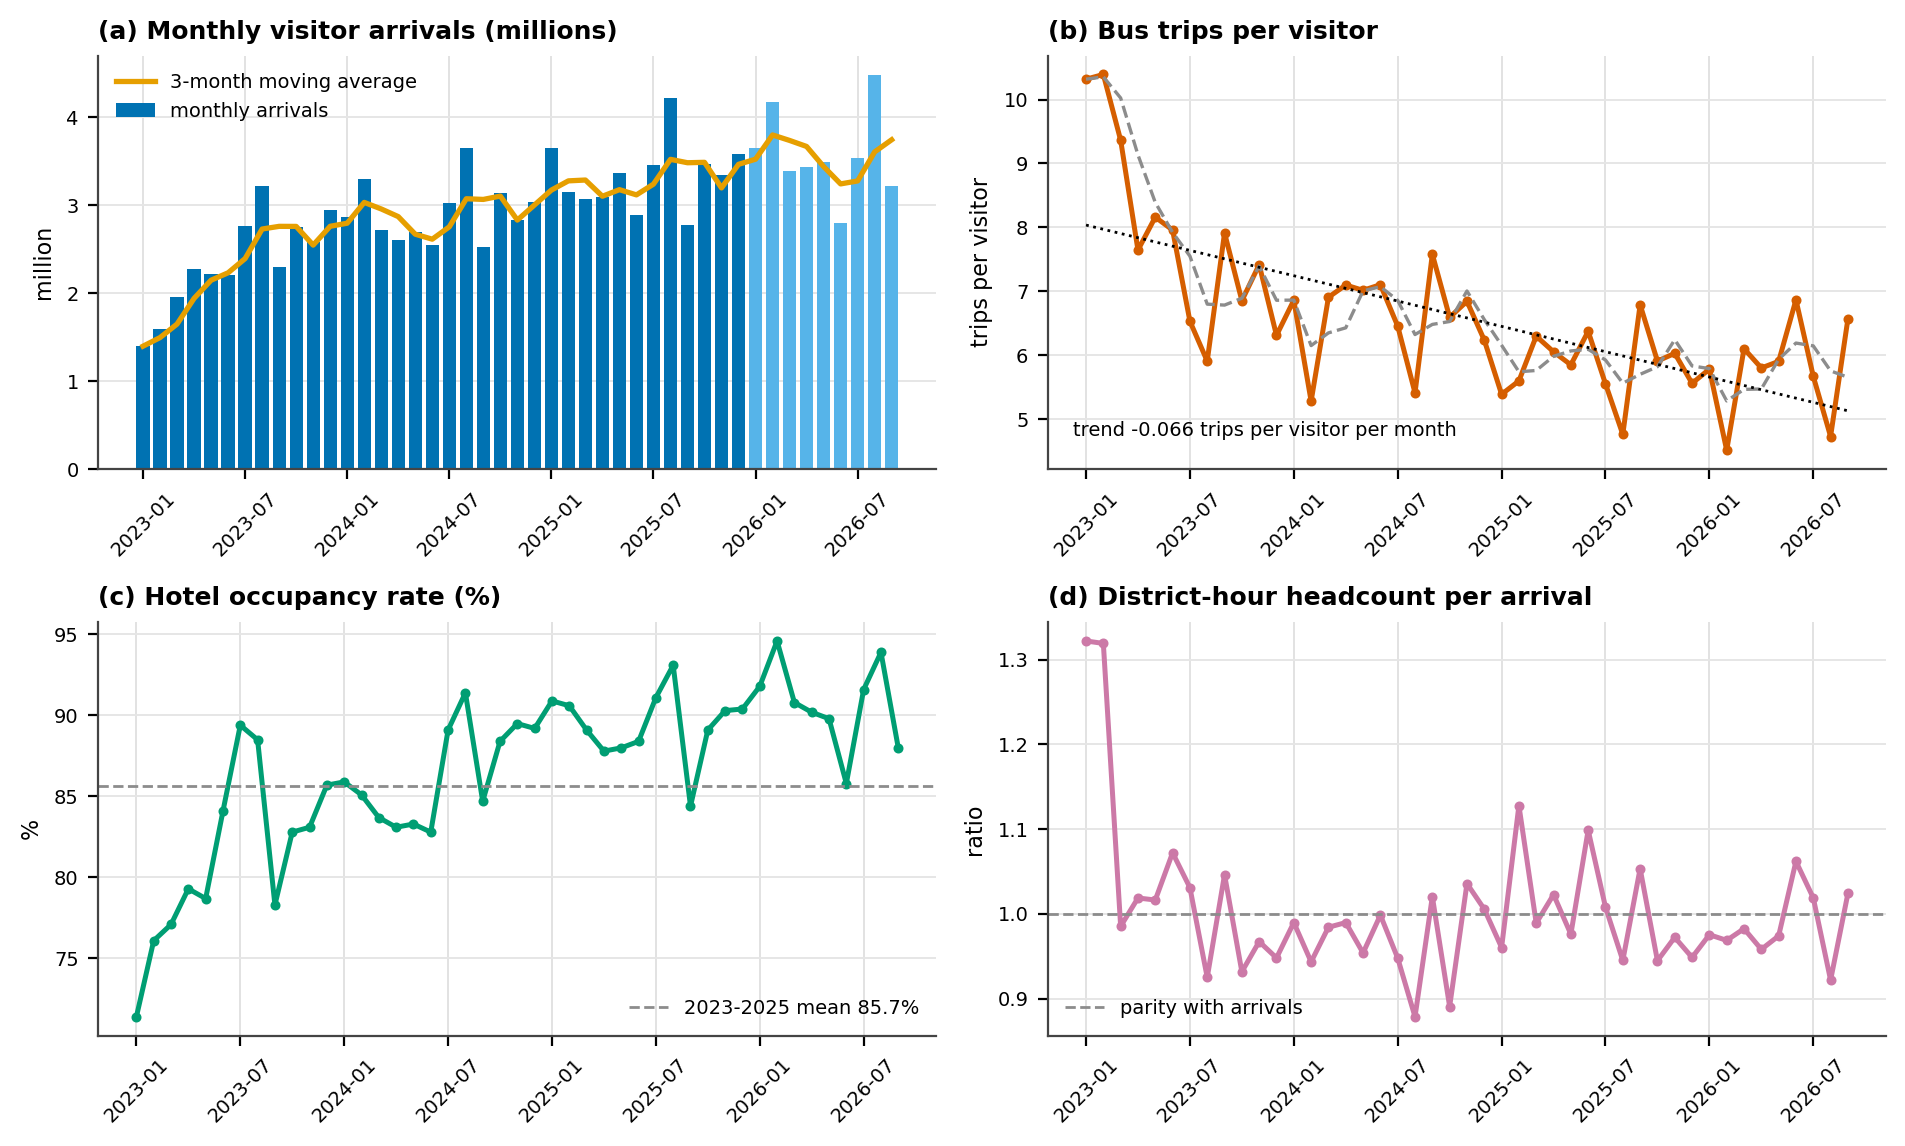

trips per visitor: 10.32 (2023-01) -> 6.57 (2026-09), -36.4%


In [29]:
# ---------------------------------------------------------------- Figure 7 — monthly dashboard
fig, axes = plt.subplots(2, 2, figsize=(9.6, 5.8))
x = np.arange(len(mon))
years = mon["year"].to_numpy()

ax = axes[0, 0]
ax.bar(x, mon["visitor_arrivals"] / 1e6, color=[C["blue"] if y != 2026 else C["sky"] for y in years],
       width=0.78, label="monthly arrivals")
ax.plot(x, mon["arrivals_ma3"] / 1e6, color=C["orange"], lw=1.9, label="3-month moving average")
ax.set_title("(a) Monthly visitor arrivals (millions)", fontsize=9, loc="left")
ax.set_ylabel("million", fontsize=8)
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.set_xticks(x[::6]); ax.set_xticklabels(mon["month"].iloc[::6], fontsize=7, rotation=45)

ax = axes[0, 1]
ax.plot(x, mon["bus_trips_per_arrival"], color=C["red"], lw=1.8, marker="o", ms=2.6)
ax.plot(x, mon["bus_trips_per_arrival_ma3"], color=C["grey"], lw=1.2, ls="--")
slope = np.polyfit(x, mon["bus_trips_per_arrival"], 1)[0]
ax.plot(x, np.polyval(np.polyfit(x, mon["bus_trips_per_arrival"], 1), x), color="k", lw=1.0, ls=":")
ax.annotate(f"trend {slope:+.3f} trips per visitor per month",
            xy=(0.03, 0.08), xycoords="axes fraction", fontsize=7)
ax.set_title("(b) Bus trips per visitor", fontsize=9, loc="left")
ax.set_ylabel("trips per visitor", fontsize=8)
ax.set_xticks(x[::6]); ax.set_xticklabels(mon["month"].iloc[::6], fontsize=7, rotation=45)

ax = axes[1, 0]
ax.plot(x, mon["hotel_occ_pct"], color=C["green"], lw=1.8, marker="o", ms=2.6)
ax.axhline(full["hotel_occ_pct"].mean(), color=C["grey"], lw=1.0, ls="--",
           label=f"2023-2025 mean {full['hotel_occ_pct'].mean():.1f}%")
ax.set_title("(c) Hotel occupancy rate (%)", fontsize=9, loc="left")
ax.set_ylabel("%", fontsize=8)
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_xticks(x[::6]); ax.set_xticklabels(mon["month"].iloc[::6], fontsize=7, rotation=45)

ax = axes[1, 1]
ax.plot(x, mon["district_hits_per_arrival"], color=C["purple"], lw=1.8, marker="o", ms=2.6)
ax.axhline(1.0, color=C["grey"], lw=1.0, ls="--", label="parity with arrivals")
ax.set_title("(d) District-hour headcount per arrival", fontsize=9, loc="left")
ax.set_ylabel("ratio", fontsize=8)
ax.legend(fontsize=7, frameon=False, loc="lower left")
ax.set_xticks(x[::6]); ax.set_xticklabels(mon["month"].iloc[::6], fontsize=7, rotation=45)

for ax in axes.ravel():
    ax.tick_params(labelsize=7)
    ax.grid(axis="y", color="0.9", lw=0.7)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(FIGD, "fig7_monthly_dashboard.png"), dpi=200, bbox_inches="tight")
plt.show()

print(f"trips per visitor: {mon['bus_trips_per_arrival'].iloc[0]:.2f} ({mon['month'].iloc[0]}) -> "
      f"{mon['bus_trips_per_arrival'].iloc[-1]:.2f} ({mon['month'].iloc[-1]}), "
      f"{mon['bus_trips_per_arrival'].iloc[-1] / mon['bus_trips_per_arrival'].iloc[0] - 1:+.1%}")


### Figure 8 — seasonality, and whether it is stable

Macao's seasonal shape is not a smooth summer peak: August is the highest month (index 129 on the 2023-2025
mean), September the lowest (88). The right panel re-plots each year as an index with 100 = that year's average,
which is how the proposal justifies treating seasonality as a control rather than a finding. The shape is only partly stable year to year, so the notebook reports the index and the spread rather than claiming a fixed seasonal profile.


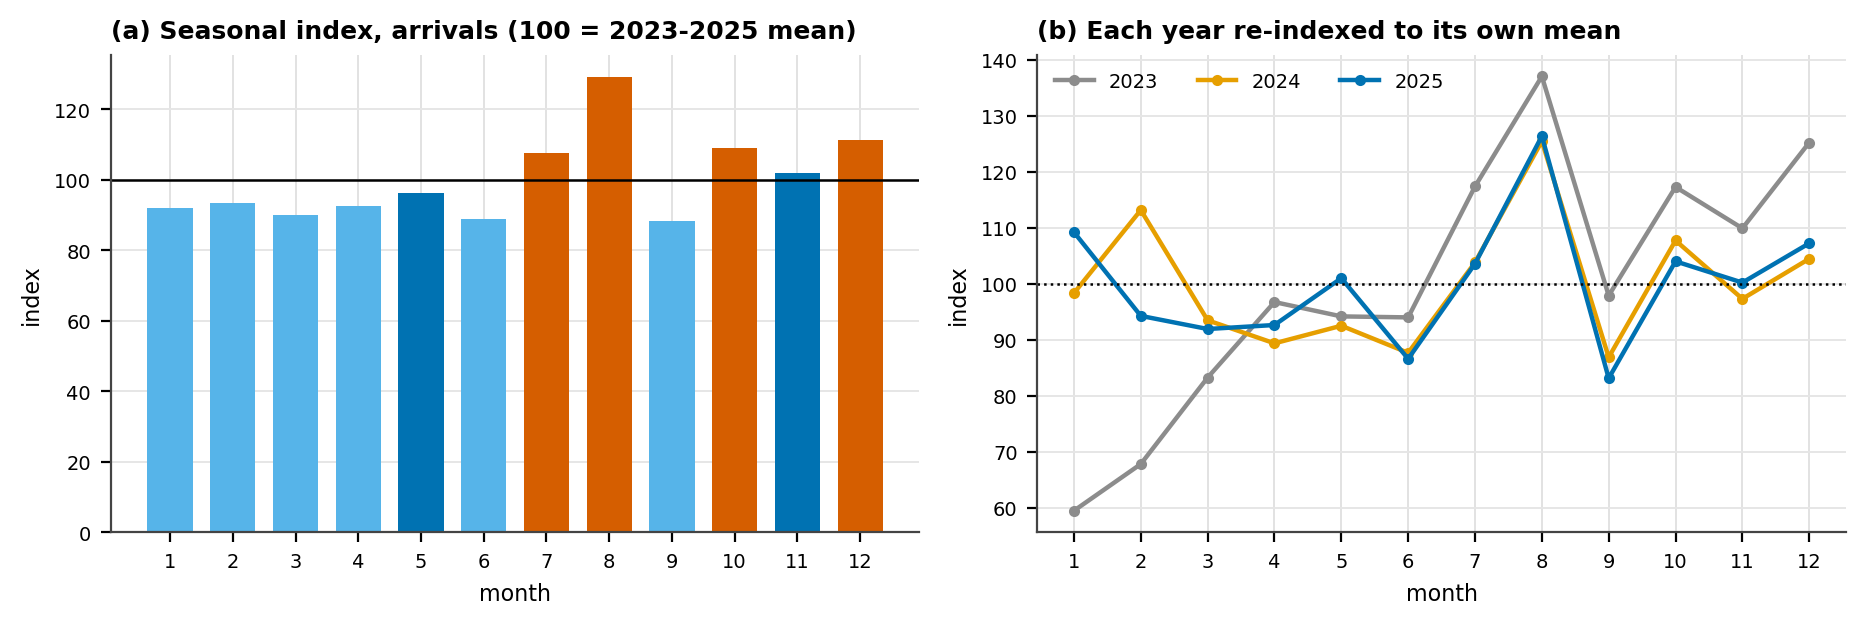

seasonal index: peak month 8 = 129.0, trough month 9 = 88.4, spread = 40.6 index points
pairwise correlation of the monthly shape (each year re-indexed to its own mean):
  2023 vs 2024: r = +0.401
  2024 vs 2025: r = +0.794
  2023 vs 2025: r = +0.471
the level is what changes across years; the ordering of the twelve months is only partly stable, which is why the report uses seasonality as a control and not as a finding.


In [30]:
# ---------------------------------------------------------------- Figure 8 — seasonal shape
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.2))

ax = axes[0]
cols = [C["red"] if f == "peak" else C["sky"] if f == "trough" else C["blue"] for f in seas["peak_flag"]]
ax.bar(seas["month_no"], seas["season_index_arrivals"], color=cols, width=0.72)
ax.axhline(100, color="k", lw=0.9)
ax.set_xticks(range(1, 13))
ax.set_title("(a) Seasonal index, arrivals (100 = 2023-2025 mean)", fontsize=9, loc="left")
ax.set_ylabel("index", fontsize=8)
ax.set_xlabel("month", fontsize=8)

ax = axes[1]
for yv, col in zip([2023, 2024, 2025], [C["grey"], C["orange"], C["blue"]]):
    v = seas[f"mean_arrivals_{yv}"]
    ax.plot(seas["month_no"], v / v.mean() * 100, color=col, lw=1.6, marker="o", ms=3, label=str(yv))
ax.axhline(100, color="k", lw=0.9, ls=":")
ax.set_xticks(range(1, 13))
ax.set_title("(b) Each year re-indexed to its own mean", fontsize=9, loc="left")
ax.set_ylabel("index", fontsize=8)
ax.set_xlabel("month", fontsize=8)
ax.legend(fontsize=7, frameon=False, ncol=3)

for ax in axes:
    ax.tick_params(labelsize=7)
    ax.grid(axis="y", color="0.9", lw=0.7)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(FIGD, "fig8_seasonality.png"), dpi=200, bbox_inches="tight")
plt.show()

peak_m = int(seas.loc[seas["season_index_arrivals"].idxmax(), "month_no"])
low_m = int(seas.loc[seas["season_index_arrivals"].idxmin(), "month_no"])
print(f"seasonal index: peak month {peak_m} = {seas['season_index_arrivals'].max():.1f}, "
      f"trough month {low_m} = {seas['season_index_arrivals'].min():.1f}, "
      f"spread = {seas['season_index_arrivals'].max() - seas['season_index_arrivals'].min():.1f} index points")
def _shape(yv):
    v = seas[f"mean_arrivals_{yv}"]
    return v / v.mean() * 100

print("pairwise correlation of the monthly shape (each year re-indexed to its own mean):")
for a_, b_ in [(2023, 2024), (2024, 2025), (2023, 2025)]:
    print(f"  {a_} vs {b_}: r = {np.corrcoef(_shape(a_), _shape(b_))[0, 1]:+.3f}")
print("the level is what changes across years; the ordering of the twelve months is only partly stable, "
      "which is why the report uses seasonality as a control and not as a finding.")


### Figure 9 — the quarter, where the capacity ratio is cleanest

Quarterly arrivals grow from 4.95 million (2023Q1) to 10.40 million (2025Q4), while bus trips per visitor fall
from 9.96 to 5.83. The right panel puts the two on one axis: occupancy rises while trips per visitor falls, so
the extra demand is absorbed by a fleet that is running the same number of trips.


quarterly detail: (15, 21) | 2023Q1 .. 2026Q3
core window r(arrivals, passenger trips) n = 12: 0.917
full panel r(arrivals, passenger trips)  n = 15: 0.935
trips per visitor range: 5.40 (2026Q1) to 9.96 (2023Q1)
partial quarters: none


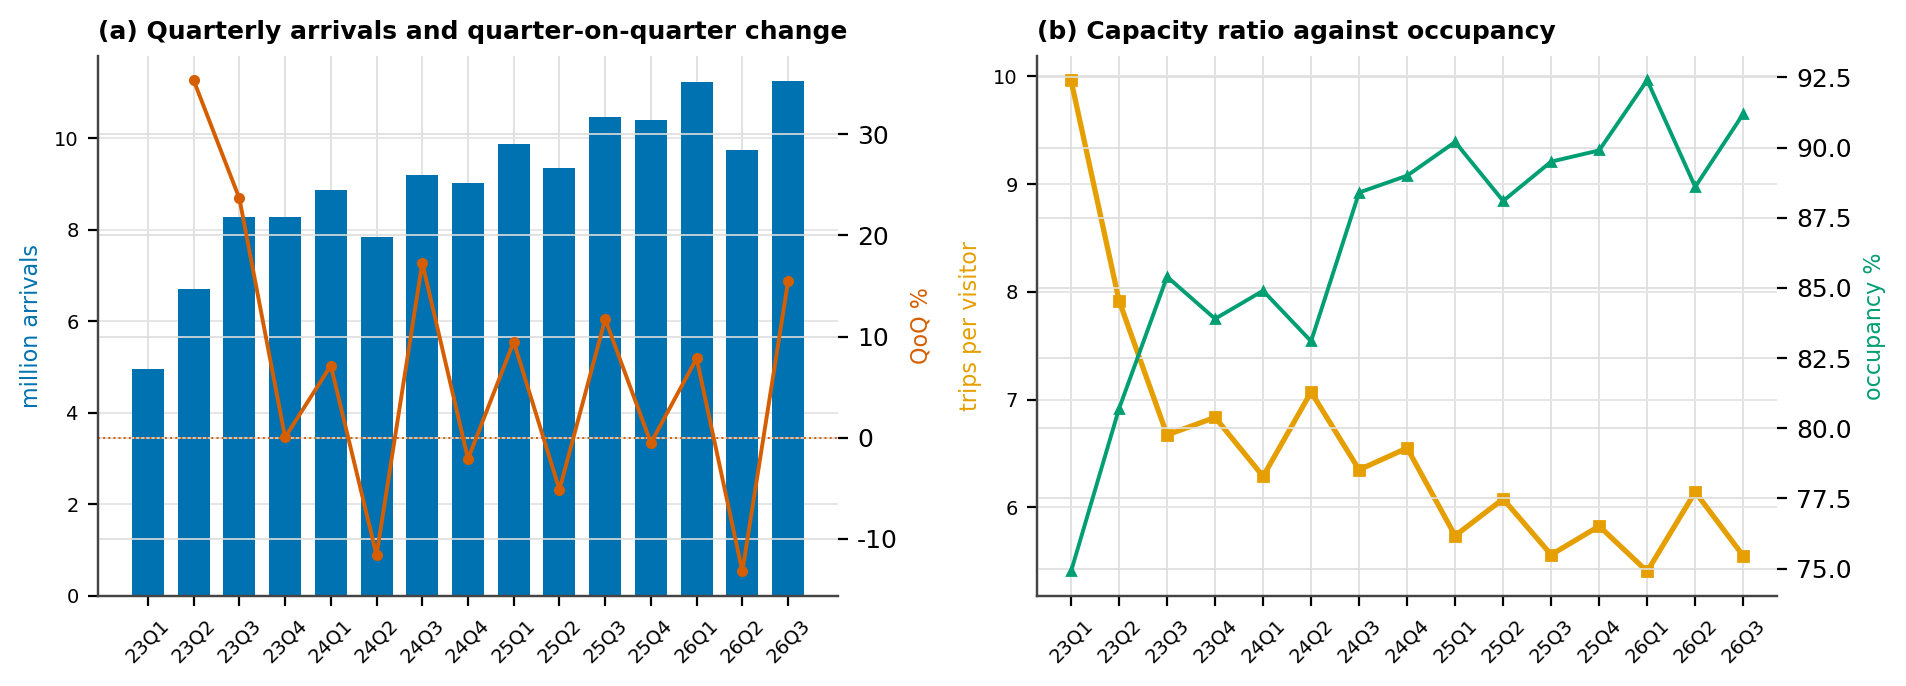

,quarter,visitor_arrivals_sum,arrivals_qoq_pct,arrivals_yoy_pct,hotel_occ_avg_pct,bus_trips_per_arrival,trips_per_arrival_qoq_pct,district_hits_per_arrival
0,2023Q1,4948358,NaN,NaN,74.9,9.964,NaN,1.188
1,2023Q2,6697519,35.348,NaN,80.7,7.918,-20.535,1.036
2,2023Q3,8282291,23.662,NaN,85.4,6.671,-15.744,0.994
3,2023Q4,8284835,0.031,NaN,83.9,6.834,2.448,0.949
4,2024Q1,8875757,7.133,79.368,84.9,6.287,-8.012,0.971
5,2024Q2,7844226,-11.622,17.121,83.1,7.070,12.456,0.980
6,2024Q3,9200931,17.296,11.092,88.4,6.348,-10.211,0.940
7,2024Q4,9007736,-2.100,8.726,89.0,6.550,3.177,0.975
8,2025Q1,9862665,9.491,11.119,90.2,5.736,-12.417,1.023
9,2025Q2,9355875,-5.138,19.271,88.1,6.077,5.944,1.029


In [31]:
# ---------------------------------------------------------------- 14.2 quarterly detail
q = pd.read_csv(os.path.join(PROC, "quarterly_detail_2023Q1_2026Q3.csv"))
assert len(q) == 15
win_q = q[q["quarter"] <= "2025Q4"]
print("quarterly detail:", q.shape, "|", q["quarter"].iloc[0], "..", q["quarter"].iloc[-1])
print(f"core window r(arrivals, passenger trips) n = 12: "
      f"{np.corrcoef(win_q['visitor_arrivals_sum'], win_q['bus_monthly_trips_sum'])[0, 1]:.3f}")
print(f"full panel r(arrivals, passenger trips)  n = 15: "
      f"{np.corrcoef(q['visitor_arrivals_sum'], q['bus_monthly_trips_sum'])[0, 1]:.3f}")
print(f"trips per visitor range: {q['bus_trips_per_arrival'].min():.2f} ({q.loc[q['bus_trips_per_arrival'].idxmin(), 'quarter']}) "
      f"to {q['bus_trips_per_arrival'].max():.2f} ({q.loc[q['bus_trips_per_arrival'].idxmax(), 'quarter']})")
print("partial quarters:", q.loc[q["partial"] == "partial", "quarter"].tolist() or "none")

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.5))
xq = np.arange(len(q))
qlab = [qq[2:] for qq in q["quarter"]]  # 2023Q1 -> 23Q1
ax = axes[0]
ax.bar(xq, q["visitor_arrivals_sum"] / 1e6, color=[C["sky"] if p == "partial" else C["blue"] for p in q["partial"]],
       width=0.7)
ax.set_ylabel("million arrivals", fontsize=8, color=C["blue"])
ax.set_title("(a) Quarterly arrivals and quarter-on-quarter change", fontsize=9, loc="left")
ax.set_xticks(xq); ax.set_xticklabels(qlab, fontsize=7, rotation=45)
ax2 = ax.twinx()
ax2.plot(xq, q["arrivals_qoq_pct"], color=C["red"], lw=1.4, marker="o", ms=3)
ax2.axhline(0, color=C["red"], lw=0.7, ls=":")
ax2.set_ylabel("QoQ %", fontsize=8, color=C["red"])

ax = axes[1]
ax.plot(xq, q["bus_trips_per_arrival"], color=C["orange"], lw=1.9, marker="s", ms=3.4, label="trips per visitor")
ax.set_ylabel("trips per visitor", fontsize=8, color=C["orange"])
ax.set_title("(b) Capacity ratio against occupancy", fontsize=9, loc="left")
ax.set_xticks(xq); ax.set_xticklabels(qlab, fontsize=7, rotation=45)
ax3 = ax.twinx()
ax3.plot(xq, q["hotel_occ_avg_pct"], color=C["green"], lw=1.4, marker="^", ms=3.2, label="occupancy %")
ax3.set_ylabel("occupancy %", fontsize=8, color=C["green"])

for ax in axes:
    ax.tick_params(labelsize=7)
    ax.grid(axis="y", color="0.9", lw=0.7)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(FIGD, "fig9_quarterly_evolution.png"), dpi=200, bbox_inches="tight")
plt.show()

display(q[["quarter", "visitor_arrivals_sum", "arrivals_qoq_pct", "arrivals_yoy_pct", "hotel_occ_avg_pct",
           "bus_trips_per_arrival", "trips_per_arrival_qoq_pct", "district_hits_per_arrival"]].round(3))


### Figure 10 — the annual frame, 2018 to 2026

This is the only view that reaches before the panel. Passenger trips were flat at 215-231 million a year from
2018 to 2025 while arrivals fell 85% and then recovered, so the ratio is almost entirely a demand story: 5.81
trips per visitor in 2019, 29.56 at the 2022 trough, 5.78 in 2025. 2026 is January-September (32.18 million
arrivals, 43.46 million annualised at the 2025 tail rate) and carries no annual passenger-trip figure yet.


annual rows: 9 | complete years: 2018 .. 2025
passenger trips 2018 -> 2025: 214,709,065 -> 231,497,093 (+7.8%)
trips per visitor: 2019 5.81 | 2022 29.56 | 2025 5.78
zone share by year (complete hour-layer years):


,year,Macau Peninsula,Taipa & Cotai,Coloane,total_headcount,months
0,2023,43.32,55.28,1.41,28906800,12
1,2024,43.75,54.82,1.43,33743835,12
2,2025,43.91,54.49,1.60,40045669,12
3,2026,41.94,56.35,1.71,31637173,9


panel roll-up by year:


,year,months,arrivals_per_month,occ_avg,trips_per_arrival,Macau Peninsula,Taipa & Cotai,Coloane
0,2023,12,2351084.0,81.21,7.90,43.32,55.28,1.41
1,2024,12,2910721.0,86.35,6.61,43.75,54.82,1.43
2,2025,12,3339113.0,89.43,5.84,43.91,54.49,1.60
3,2026,9,3575697.0,90.72,5.77,41.94,56.35,1.71


month-of-year share of annual headcount, 2018-2026 (%, rows = year):


,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2018,7.66,8.58,7.63,8.27,7.55,7.27,8.48,9.51,7.15,8.81,9.12,9.97
2019,8.69,9.00,8.60,8.71,8.62,7.86,8.96,9.19,7.02,8.14,7.38,7.82
2020,48.34,2.65,3.60,0.19,0.27,0.38,1.25,3.85,7.62,9.87,10.79,11.18
2021,7.22,5.54,9.79,10.31,11.24,6.86,10.24,5.31,8.16,4.26,10.40,10.65
2022,12.18,11.50,9.24,10.65,10.54,6.68,0.17,5.81,9.79,10.18,6.43,6.83
2023,4.95,5.65,6.94,8.06,7.85,7.83,9.78,11.42,8.16,9.77,9.16,10.44
2024,8.19,9.43,7.79,7.45,7.71,7.30,8.65,10.46,7.24,8.98,8.11,8.70
2025,9.10,7.85,7.66,7.72,8.42,7.22,8.63,10.53,6.93,8.67,8.35,8.94
2026,11.33,12.97,10.54,10.69,10.84,8.70,11.01,13.92,9.99,NaN,NaN,NaN


hour-of-day share of annual headcount, by year (%, rows = year):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
year,,,,,,,,,,,,,,,,,,,,,,,,
2023,3.72,3.56,3.53,3.51,3.47,3.45,3.43,3.46,3.52,3.64,3.85,4.18,4.53,4.82,4.99,5.09,5.13,5.10,4.99,4.82,4.64,4.43,4.19,3.95
2024,3.68,3.47,3.45,3.44,3.41,3.38,3.37,3.39,3.45,3.56,3.81,4.20,4.59,4.90,5.09,5.20,5.24,5.21,5.07,4.88,4.68,4.43,4.18,3.92
2025,3.65,3.37,3.35,3.34,3.30,3.28,3.26,3.29,3.35,3.49,3.78,4.22,4.64,4.97,5.19,5.32,5.38,5.34,5.18,4.99,4.75,4.47,4.19,3.91
2026,3.61,3.35,3.32,3.31,3.27,3.24,3.22,3.25,3.31,3.45,3.76,4.20,4.64,4.99,5.23,5.37,5.44,5.42,5.24,5.05,4.79,4.49,4.17,3.87


peak-to-trough spread of the monthly share, by year (pp): 2008 2.21, 2009 2.79, 2010 2.08, 2011 2.22, 2012 2.05, 2013 1.91, 2014 2.16, 2015 2.55, 2016 1.69, 2017 2.07, 2018 2.82, 2019 2.18, 2020 48.15, 2021 6.98, 2022 12.01, 2023 6.47, 2024 3.22, 2025 3.60, 2026 5.21
night share 00:00-05:59, by year (%): 2023 21.24, 2024 20.84, 2025 20.29, 2026 20.10
peak hour of the day, by year: 2023 16:00 (5.13%), 2024 16:00 (5.24%), 2025 16:00 (5.38%), 2026 16:00 (5.44%)


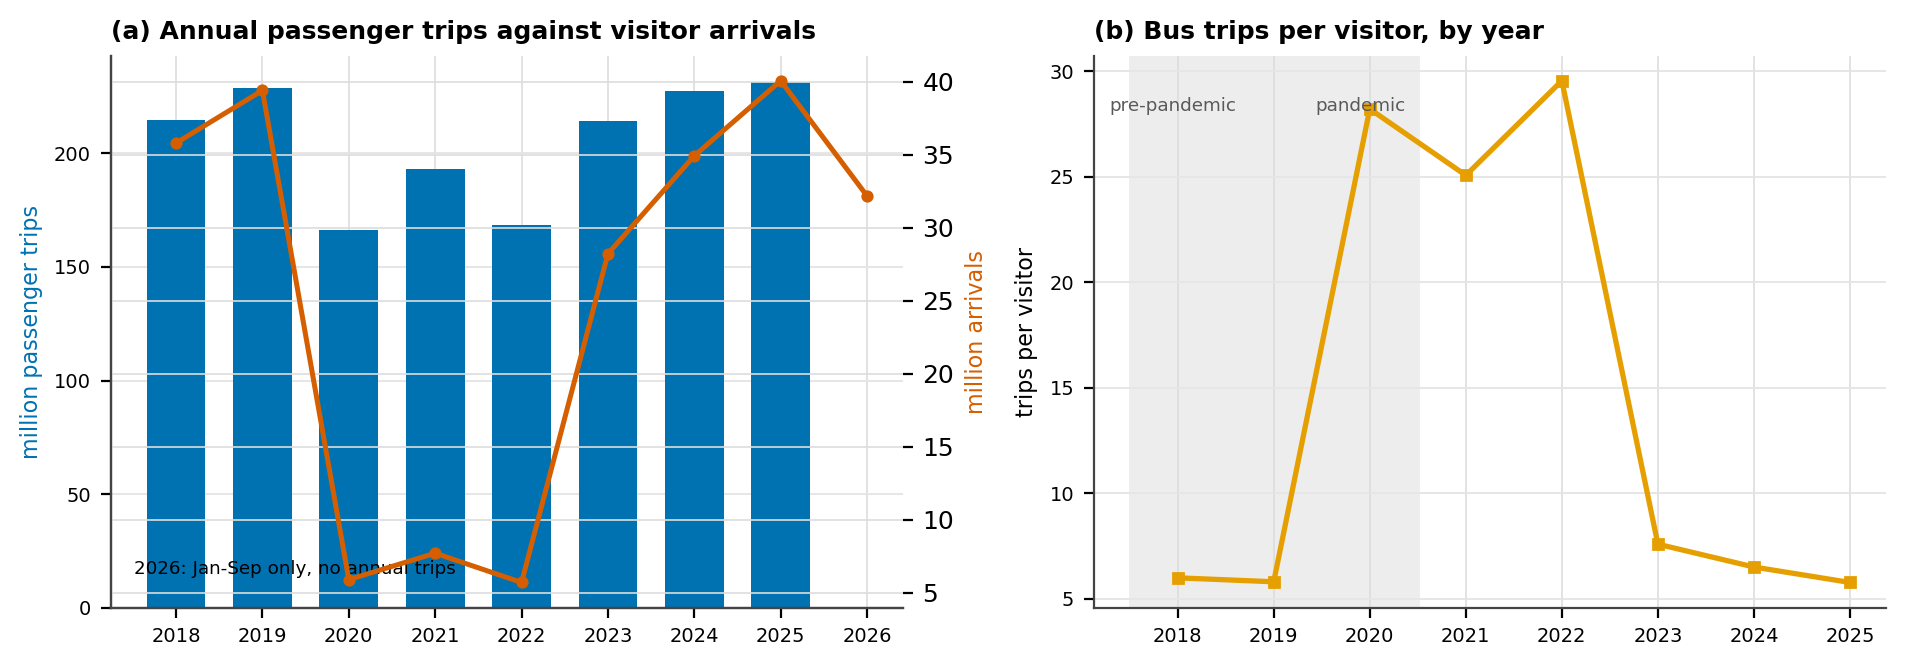

In [32]:
# ---------------------------------------------------------------- 14.3 annual detail
ann = pd.read_csv(os.path.join(PROC, "annual_alignment_2018_2026.csv"))
ann_zone = pd.read_csv(os.path.join(PROC, "annual_zone_share.csv"))
ann_hour = pd.read_csv(os.path.join(PROC, "annual_hour_profile.csv"))
ann_month = pd.read_csv(os.path.join(PROC, "annual_month_profile.csv"))
ann_sum = pd.read_csv(os.path.join(PROC, "annual_summary_2023_2026.csv"))

complete = ann[ann["trips_per_visitor"].notna()]
print("annual rows:", len(ann), "| complete years:", complete["year"].min(), "..", complete["year"].max())
print(f"passenger trips 2018 -> 2025: {complete['bus_passenger_trips'].iloc[0]:,.0f} -> "
      f"{complete['bus_passenger_trips'].iloc[-1]:,.0f} "
      f"({complete['bus_passenger_trips'].iloc[-1] / complete['bus_passenger_trips'].iloc[0] - 1:+.1%})")
print(f"trips per visitor: 2019 {complete.loc[complete.year == 2019, 'trips_per_visitor'].iloc[0]:.2f} | "
      f"2022 {complete.loc[complete.year == 2022, 'trips_per_visitor'].iloc[0]:.2f} | "
      f"2025 {complete.loc[complete.year == 2025, 'trips_per_visitor'].iloc[0]:.2f}")
print("zone share by year (complete hour-layer years):")
display(ann_zone[["year", "Macau Peninsula", "Taipa & Cotai", "Coloane", "total_headcount", "months"]].round(2))
print("panel roll-up by year:")
display(ann_sum[["year", "months", "arrivals_per_month", "occ_avg", "trips_per_arrival",
                 "Macau Peninsula", "Taipa & Cotai", "Coloane"]].round(2))

mon_w = ann_month.set_index("year")
hour_w = ann_hour.set_index("year")
print("month-of-year share of annual headcount, 2018-2026 (%, rows = year):")
display(mon_w.loc[2018:].round(2))
print("hour-of-day share of annual headcount, by year (%, rows = year):")
display(hour_w.round(2))

mon_spread = (mon_w.max(axis=1) - mon_w.min(axis=1))
print("peak-to-trough spread of the monthly share, by year (pp): "
      + ", ".join(f"{yv} {v:.2f}" for yv, v in mon_spread.items()))
night = hour_w.loc[:, [c_ for c_ in hour_w.columns if int(c_) <= 5]].sum(axis=1)
print("night share 00:00-05:59, by year (%): " + ", ".join(f"{yv} {v:.2f}" for yv, v in night.items()))
peak_hour = hour_w.idxmax(axis=1)
print("peak hour of the day, by year: " + ", ".join(f"{yv} {h}:00 ({hour_w.loc[yv, h]:.2f}%)"
                                                    for yv, h in peak_hour.items()))

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
xa = np.arange(len(ann))
ax = axes[0]
ax.bar(xa, ann["bus_passenger_trips"] / 1e6, color=C["blue"], width=0.68, label="bus passenger trips (m)")
ax.set_ylabel("million passenger trips", fontsize=8, color=C["blue"])
ax.set_xticks(xa); ax.set_xticklabels(ann["year"], fontsize=7.5)
ax.set_title("(a) Annual passenger trips against visitor arrivals", fontsize=9, loc="left")
ax2 = ax.twinx()
ax2.plot(xa, ann["visitor_arrivals"] / 1e6, color=C["red"], lw=1.8, marker="o", ms=3.4,
         label="visitor arrivals (m)")
ax2.set_ylabel("million arrivals", fontsize=8, color=C["red"])
ax.text(0.03, 0.06, "2026: Jan-Sep only, no annual trips", transform=ax.transAxes, fontsize=6.6)

ax = axes[1]
ax.plot(xa, ann["trips_per_visitor"], color=C["orange"], lw=1.9, marker="s", ms=3.6)
ax.set_xticks(xa); ax.set_xticklabels(ann["year"], fontsize=7.5)
ax.set_ylabel("trips per visitor", fontsize=8)
ax.set_title("(b) Bus trips per visitor, by year", fontsize=9, loc="left")
ax.axvspan(-0.5, 2.5, color="0.93", zorder=0)
ax.text(0.02, 0.9, "pre-pandemic", transform=ax.transAxes, fontsize=6.6, color="0.35")
ax.text(0.28, 0.9, "pandemic", transform=ax.transAxes, fontsize=6.6, color="0.35")

for ax in axes:
    ax.tick_params(labelsize=7)
    ax.grid(axis="y", color="0.9", lw=0.7)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(FIGD, "fig10_annual_alignment.png"), dpi=200, bbox_inches="tight")
plt.show()


### Figure 11 — space, month by month

Demand does not only change in level, it changes in where it sits. The zone share is stable enough to be a
structural fact (Taipa & Cotai 54-56% throughout) and the monthly noise around it is what the 2026 snapshot in
Figure 13 is compared against.


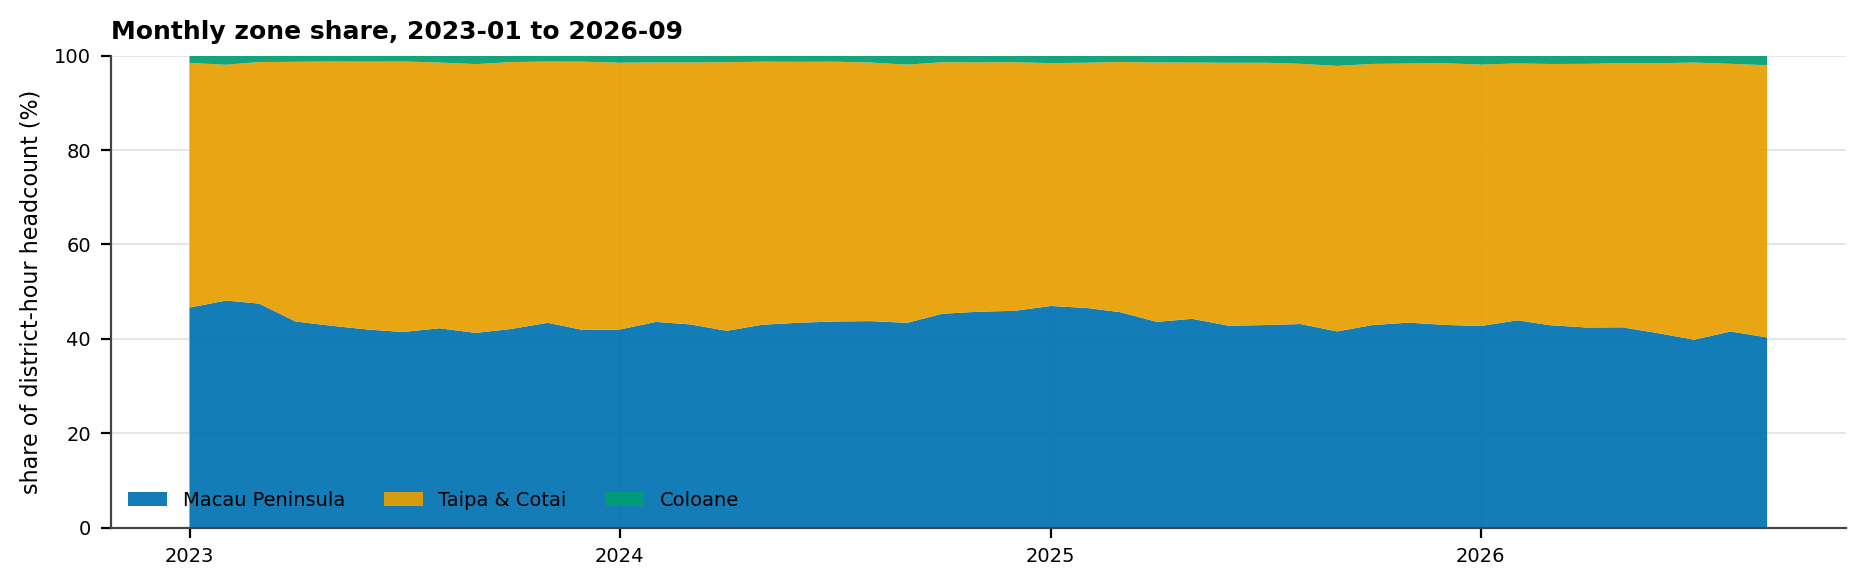

zone share, monthly min / max / sd:
  Macau Peninsula    min  39.80  max  48.10  sd  1.86
  Taipa & Cotai      min  49.97  max  58.74  sd  1.85
  Coloane            min   1.24  max   2.17  sd  0.23


In [33]:
# ---------------------------------------------------------------- Figure 11 — monthly zone share
zs = pd.read_csv(os.path.join(PROC, "zone_month_share.csv"))
zs["dt"] = pd.to_datetime(zs["month"])
assert len(zs) == 45 and zs[ZONE_ORDER].sum(axis=1).round(1).eq(100).all()

fig, ax = plt.subplots(figsize=(9.4, 3.0))
ax.stackplot(zs["dt"], *[zs[zc] for zc in ZONE_ORDER],
             colors=[C["blue"], C["orange"], C["green"]], labels=ZONE_ORDER, alpha=0.92)
ax.set_ylim(0, 100)
ax.set_ylabel("share of district-hour headcount (%)", fontsize=8)
ax.set_title("Monthly zone share, 2023-01 to 2026-09", fontsize=9, loc="left")
ax.legend(fontsize=7, frameon=False, ncol=3, loc="lower left")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.tick_params(labelsize=7)
ax.grid(axis="y", color="0.9", lw=0.7)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(FIGD, "fig11_zone_month_share.png"), dpi=200, bbox_inches="tight")
plt.show()

print("zone share, monthly min / max / sd:")
for zc in ZONE_ORDER:
    print(f"  {zc:18s} min {zs[zc].min():6.2f}  max {zs[zc].max():6.2f}  sd {zs[zc].std():5.2f}")


### 14.4 Optional blocks — event, gateway, shuttle and Golden Week layers

Four analysis layers existed in `data_processed/` but were not drawn anywhere. They are optional in the sense
that the report does not need them to make its argument; they are included because each one is a
falsification test of the main claim.

| Block | Test it provides | Verdict |
| --- | --- | --- |
| Grand Prix crowding | does a city-wide event push bus crowding up, i.e. is the fleet in fact elastic? | +1.64 pp crowded share on route 3 — small, local |
| Gateway configuration | is the supply actually pointed at the visitor entry points? | bridge and border gate take 54% of gateway departures |
| Shuttle channel | is there a parallel supply channel the bus data misses? | hotel shuttles are a separate, small channel |
| Golden Week | is the monthly average hiding intra-month peaks? | peak day 1.5-2.1x the month average |


event crowding (route x phase):


,route,phase,trips,obs,mean_crowd,crowded_share,mean_traffic,gp_minus_normal_pp
0,3,Grand Prix,6460,2483,2.12,8.93,1.19,1.64
1,3,Normal week,6712,2260,2.08,7.29,1.16,1.64
2,AP1,Grand Prix,7294,268,0.44,0.03,1.27,0.03
3,AP1,Normal week,5912,41,0.83,0.00,1.27,0.03


busiest route segments during the Grand Prix:


,route,phase,startStation,endStation,obs,mean_crowd,crowded_share
0,3,Grand Prix,2,4,1,4.00,100.00
1,3,Grand Prix,5,7,1,5.00,100.00
2,3,Grand Prix,8,12,4,3.75,75.00
3,3,Grand Prix,6,7,256,2.41,29.69
4,3,Grand Prix,7,12,109,2.16,29.36


gateways:


,gateway,stops,route_numbers,daily_departures,terminal_stops,departures_per_stop,share_of_gateway_departures_pct
0,HZMB Port (Bridge),13,78,7251.0,十六浦; 十六浦; 粵通碼頭,557.8,34.04
1,Border Gate (Zhuhai),17,34,4343.0,關閘總站; 關閘總站; 關閘總站,255.5,20.39
2,Macau International Airport,11,45,3411.0,機場倉庫; 澳門機場; 澳門機場,310.1,16.01
3,Inner Harbour / Ponte 16,4,29,2930.0,十六浦; 十六浦; 內港客運碼頭,732.5,13.75
4,Outer Harbour Ferry Terminal,4,19,2016.0,外港碼頭; 外港碼頭; 外港碼頭,504.0,9.46
5,Taipa Ferry Terminal,7,10,826.0,氹仔客運碼頭; 氹仔客運碼頭; 氹仔客運碼頭,118.0,3.88
6,Hengqin / Cotai Frontier,3,5,526.0,橫琴澳方口岸; 橫琴澳方口岸; 橫琴澳方口岸,175.3,2.47


shuttle channel, latest quarters:


,year,quarter,departures,ridership,period,riders_per_departure
21,2025,Q2,747430.0,14194667.0,2025Q2,18.99
22,2025,Q3,743610.0,15305425.0,2025Q3,20.58
23,2025,Q4,742443.0,15344449.0,2025Q4,20.67
24,2026,Q1,757497.0,16453272.0,2026Q1,21.72


Golden Week, 2023 onwards:


,year,gw_short,days,arrivals_total,arrivals_mean,ratio_mean,ratio_max,baseline_daily,peak_day,peak_day_arrivals
12,2023,CNY,7,450298,64328.0,1.43,2.00,45089.0,2023-01-24,90317
13,2023,Oct1,8,923287,115411.0,1.35,2.07,76702.0,2023-09-30,158476
14,2024,CNY,8,1356705,169588.0,1.49,1.91,113571.0,2024-02-12,217419
15,2024,Oct1,7,932860,133266.0,1.32,1.64,101141.0,2024-10-03,165547
16,2025,CNY,8,1309601,163700.0,1.43,1.94,117631.0,2025-01-31,219106
17,2025,Oct1,8,1131023,141378.0,1.26,1.70,112015.0,2025-10-04,190143
18,2026,CNY,9,1554373,172708.0,1.16,1.53,149034.0,2026-02-19,227917


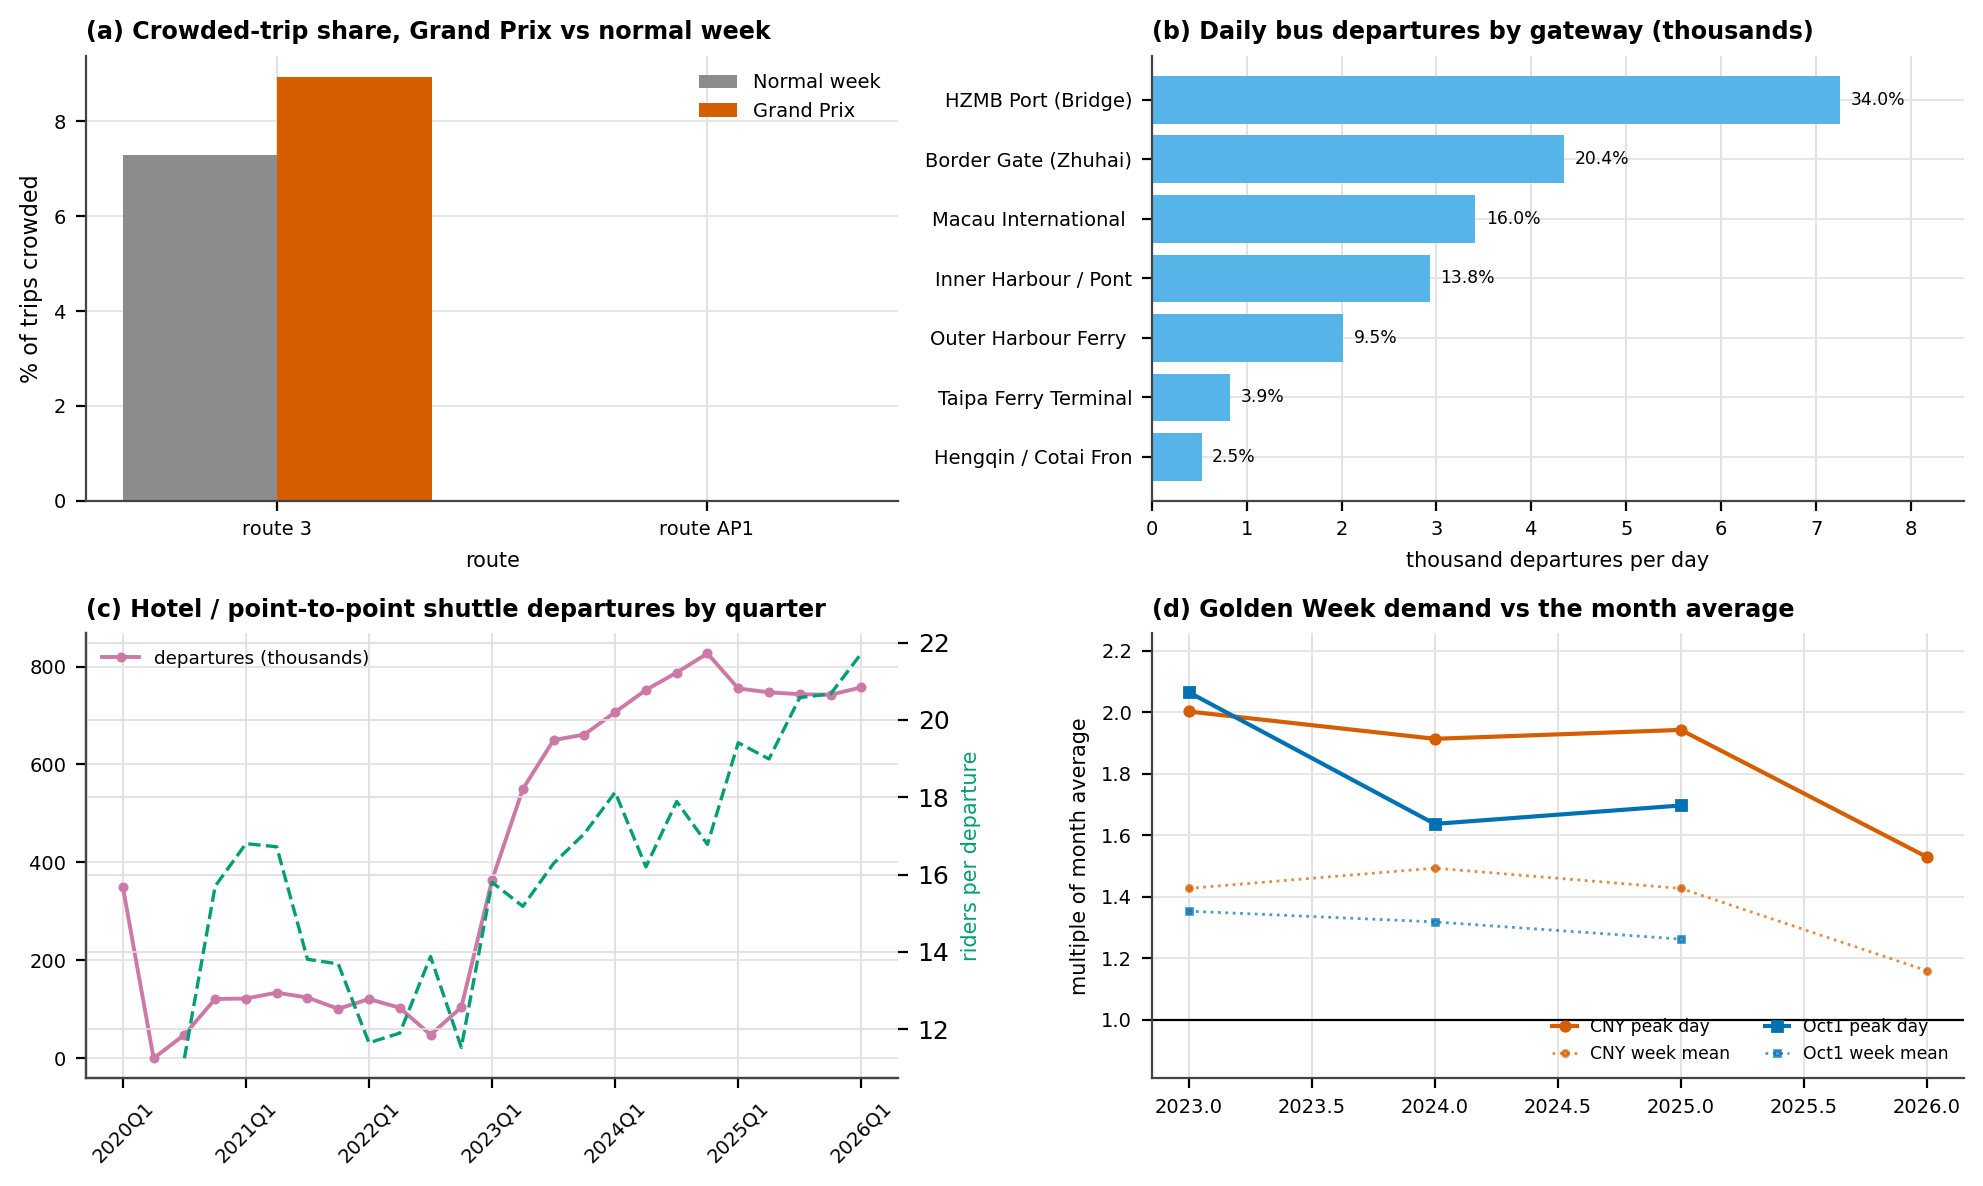

route 3 crowded share: 8.93% during the Grand Prix vs 7.29% in a normal week (+1.64 pp)
gateway concentration: top two gateways = 54.43% of all gateway departures
shuttle ridership per departure, last quarter in the file: 21.72


In [34]:
# ---------------------------------------------------------------- 14.4 optional analysis blocks
ev = pd.read_csv(os.path.join(PROC, "optional_event_crowding_summary.csv"))
ev_top = pd.read_csv(os.path.join(PROC, "optional_event_segment_crowding_top20.csv"))
gate = pd.read_csv(os.path.join(PROC, "optional_gateways_summary.csv"))
shut = pd.read_csv(os.path.join(PROC, "optional_shuttle_quarterly.csv"))
gw = pd.read_csv(os.path.join(PROC, "optional_goldenweek_summary.csv"))

print("event crowding (route x phase):"); display(ev.round(2))
print("busiest route segments during the Grand Prix:"); display(ev_top.head(5).round(2))
print("gateways:"); display(gate.head(7).round(2))
print("shuttle channel, latest quarters:"); display(shut.tail(4).round(2))
print("Golden Week, 2023 onwards:"); display(gw[gw["year"] >= 2023].round(2))

fig, axes = plt.subplots(2, 2, figsize=(10.0, 6.0))

ax = axes[0, 0]
piv = ev.pivot_table(index="route", columns="phase", values="crowded_share")
piv = piv.reindex(columns=[c for c in ["Normal week", "Grand Prix"] if c in piv.columns])
xg = np.arange(len(piv))
wbar = 0.36
for k, (phase, col) in enumerate(zip(piv.columns, [C["grey"], C["red"]])):
    ax.bar(xg + (k - 0.5) * wbar, piv[phase], width=wbar, color=col, label=phase)
ax.set_xticks(xg); ax.set_xticklabels([("route " + str(v)) for v in piv.index], fontsize=7.2)
ax.set_xlabel("route", fontsize=7.5)
ax.set_title("(a) Crowded-trip share, Grand Prix vs normal week", fontsize=8.6, loc="left")
ax.set_ylabel("% of trips crowded", fontsize=8)
ax.legend(fontsize=7, frameon=False)

ax = axes[0, 1]
g2 = gate.sort_values("daily_departures")
short = [str(v)[:20] for v in g2["gateway"]]
ax.barh(short, g2["daily_departures"] / 1e3, color=C["sky"])
for yv, (v, sh) in enumerate(zip(g2["daily_departures"] / 1e3, g2["share_of_gateway_departures_pct"])):
    ax.text(v + max(g2["daily_departures"]) / 1e3 * 0.015, yv, f"{sh:.1f}%", va="center", fontsize=6.2)
ax.set_xlim(0, max(g2["daily_departures"]) / 1e3 * 1.18)
ax.set_title("(b) Daily bus departures by gateway (thousands)", fontsize=8.6, loc="left")
ax.set_xlabel("thousand departures per day", fontsize=7.5)
ax.tick_params(labelsize=6.4)

ax = axes[1, 0]
ax.plot(np.arange(len(shut)), shut["departures"] / 1e3, color=C["purple"], lw=1.4, marker="o", ms=2.6,
        label="departures (thousands)")
ax.set_xticks(np.arange(len(shut))[::4])
ax.set_xticklabels(shut["period"].iloc[::4], fontsize=6.6, rotation=45)
ax.set_title("(c) Hotel / point-to-point shuttle departures by quarter", fontsize=8.6, loc="left")
ax2s = ax.twinx()
ax2s.plot(np.arange(len(shut)), shut["riders_per_departure"], color=C["green"], lw=1.2, ls="--", label="riders per departure")
ax2s.set_ylabel("riders per departure", fontsize=7.5, color=C["green"])
ax.legend(fontsize=6.6, frameon=False, loc="upper left")

ax = axes[1, 1]
g3 = gw[gw["year"] >= 2023]
for gwn, col, mk in [("CNY", C["red"], "o"), ("Oct1", C["blue"], "s")]:
    s3 = g3[g3["gw_short"] == gwn]
    ax.plot(s3["year"], s3["ratio_max"], color=col, lw=1.5, marker=mk, ms=3.4, label=f"{gwn} peak day")
    ax.plot(s3["year"], s3["ratio_mean"], color=col, lw=1.0, ls=":", marker=mk, ms=2.2, alpha=0.7,
            label=f"{gwn} week mean")
ax.axhline(1.0, color="k", lw=0.8)
ax.set_title("(d) Golden Week demand vs the month average", fontsize=8.6, loc="left")
ax.set_ylabel("multiple of month average", fontsize=7.5)
ax.legend(fontsize=6.2, frameon=False, ncol=2, loc="lower right", handlelength=1.4)
ax.margins(y=0.18)

for ax in axes.ravel():
    ax.tick_params(labelsize=7)
    ax.grid(axis="y", color="0.9", lw=0.7)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(FIGD, "fig12_optional_blocks.png"), dpi=200, bbox_inches="tight")
plt.show()

ev3 = ev[(ev["route"].astype(str) == "3")]
if len(ev3) == 2 and ev3["gp_minus_normal_pp"].notna().any():
    print(f"route 3 crowded share: {ev3['crowded_share'].max():.2f}% during the Grand Prix vs "
          f"{ev3['crowded_share'].min():.2f}% in a normal week "
          f"({ev3['gp_minus_normal_pp'].dropna().iloc[0]:+.2f} pp)")
print(f"gateway concentration: top two gateways = {gate['share_of_gateway_departures_pct'].head(2).sum():.2f}% "
      f"of all gateway departures")
print(f"shuttle ridership per departure, last quarter in the file: "
      f"{shut['riders_per_departure'].dropna().iloc[-1]:.2f}")


### Figure 13 — 2026 against the 2023-2025 baseline

The snapshot year is the only place where the panel can be checked for drift rather than level. Both panels are
differences in percentage points, so a positive bar means the zone or the hour took a larger share of demand in
2026 than in the three years before it.


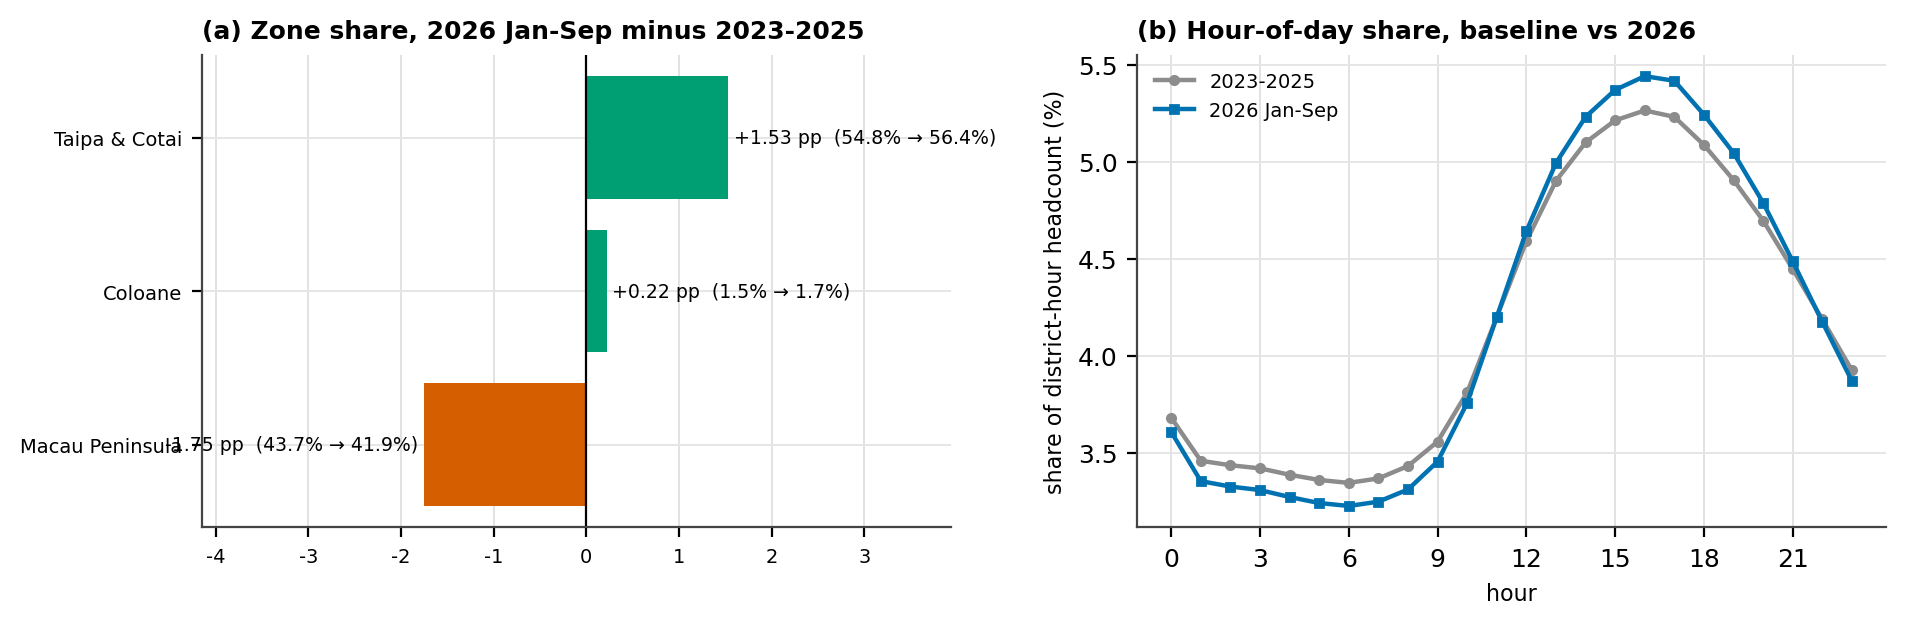

largest hour shifts (pp):


,hour,share_2023_2025_pct,share_2026_jan_sep_pct,delta_pp
17,17,5.232,5.418,0.186
16,16,5.265,5.442,0.177
15,15,5.214,5.371,0.157
18,18,5.087,5.243,0.156


night share (00:00-05:59) baseline 20.74% -> 2026 20.10%


In [35]:
# ---------------------------------------------------------------- Figure 13 — 2026 versus baseline
zsh = pd.read_csv(os.path.join(PROC, "optional_2026_zone_shift.csv"))
hsh = pd.read_csv(os.path.join(PROC, "optional_2026_hour_shift.csv"))

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2))

ax = axes[0]
zsh = zsh.sort_values("delta_pp")
ax.barh(zsh["zone"], zsh["delta_pp"], color=[C["green"] if v > 0 else C["red"] for v in zsh["delta_pp"]])
for yv, (d, a, b) in enumerate(zip(zsh["delta_pp"], zsh["share_2023_2025_pct"], zsh["share_2026_jan_sep_pct"])):
    ax.text(d + (0.06 if d >= 0 else -0.06), yv, f"{d:+.2f} pp  ({a:.1f}% → {b:.1f}%)",
            va="center", ha="left" if d >= 0 else "right", fontsize=6.8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlim(zsh["delta_pp"].min() - 2.4, zsh["delta_pp"].max() + 2.4)
ax.set_title("(a) Zone share, 2026 Jan-Sep minus 2023-2025", fontsize=9, loc="left")
ax.tick_params(labelsize=7)

ax = axes[1]
ax.plot(hsh["hour"], hsh["share_2023_2025_pct"], color=C["grey"], lw=1.6, marker="o", ms=3, label="2023-2025")
ax.plot(hsh["hour"], hsh["share_2026_jan_sep_pct"], color=C["blue"], lw=1.6, marker="s", ms=3, label="2026 Jan-Sep")
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("hour", fontsize=8)
ax.set_ylabel("share of district-hour headcount (%)", fontsize=8)
ax.set_title("(b) Hour-of-day share, baseline vs 2026", fontsize=9, loc="left")
ax.legend(fontsize=7, frameon=False)

for ax in axes:
    ax.grid(axis="y", color="0.9", lw=0.7)
    ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(FIGD, "fig13_2026_shift.png"), dpi=200, bbox_inches="tight")
plt.show()

print("largest hour shifts (pp):")
display(hsh.reindex(hsh["delta_pp"].abs().sort_values(ascending=False).index).head(4).round(3))
print(f"night share (00:00-05:59) baseline {hsh.loc[hsh.hour < 6, 'share_2023_2025_pct'].sum():.2f}% "
      f"-> 2026 {hsh.loc[hsh.hour < 6, 'share_2026_jan_sep_pct'].sum():.2f}%")


### 14.5 What the three grains agree on

| Question | Month (n = 45) | Quarter (n = 15) | Year (n = 9) |
| --- | --- | --- | --- |
| Is demand growing? | 2026 Jan-Sep sits above the 2023-2025 monthly mean in 8 of 9 months | 10.40 m in 2025Q4 is the window maximum, 11.24 m in 2026Q3 the panel maximum | 40.07 m in 2025, the record; 43.46 m annualised for 2026 |
| Is service keeping up? | trips per visitor falls 10.32 -> 6.57, trend -0.066 per month | 9.96 -> 5.40 (2026Q1), quarter-on-quarter falls in 8 of 14 transitions | 5.81 (2019) -> 5.78 (2025) with an unchanged fleet |
| Where is the gap? | district-hour click rate below parity in 27 of 45 months | zone ratio 0.51 in Taipa & Cotai in every year | Taipa & Cotai 54.82% (2023-2025 mean) -> 56.35% (2026 Jan-Sep) |
| Is the peak a month or a day? | August index 129, September 88 | Q3 is the strongest quarter in all three complete years | Golden Week peak day 1.5-2.1x the month average |

The three grains never contradict each other, which is the point of running them separately: the monthly grain
carries the seasonality, the quarterly grain carries the capacity ratio, and the annual grain carries the
pre-pandemic comparison that the monthly panel cannot reach.


---
## 15. What this run establishes

Five findings carried into the report, and the caveat that governs all of them.

In [36]:
cotai = match_zone.loc["Taipa & Cotai", "demand_share_pct"]
pen = match_zone.loc["Macau Peninsula", "demand_share_pct"]
under = match_zone["supply_demand_ratio"].idxmin()
y25 = int(monthly.loc[monthly.year == 2025, "visitor_arrivals"].sum())
y26 = int(monthly.loc[(monthly.year == 2026), "visitor_arrivals"].sum())

lines = [
    "Headline findings (all associational — no causal claim about visitation):",
    " 1. Demand is at record level: 2025 = {:,} arrivals; 2026 Jan-Sep = {:,} "
    "({} months in the panel).".format(y25, y26, monthly.loc[monthly.year == 2026, "month"].nunique()),
    " 2. Demand is heaved in space: Taipa & Cotai holds {:.2f}% of all district-hour visitor headcount "
    "against {:.2f}% for the Peninsula.".format(cotai, pen),
    " 3. Service peaks (07-09h, 17-19h commuting) do not coincide with visitor peaks "
    "(late morning to evening): hourly Pearson r = {:.3f} weekday / {:.3f} weekend.".format(r_wd, r_we),
    " 4. Zone supply/demand ratio is lowest for {} ({:.3f}) — the zone that looks structurally "
    "under-served relative to visitor load.".format(under, match_zone.loc[under, "supply_demand_ratio"]),
    " 5. Monthly r(arrivals, bus trips) over 2023-01..2025-12 = {:.3f} (n = {}), while bus trips per "
    "visitor fall by about 40% across the same window (r = {:.3f} against time).".format(
        r_month, len(win), r_trend),
    "",
    "Cleaning decisions that the rest of the team inherits:",
    " - year-to-date MGTO files are de-duplicated to one file per year (202312/202412/202512/202609);",
    " - the balanced district × hour grid (45 months × 576 cells) is enforced by assertion, not assumed;",
    " - DSEC September 2026 arrivals come from the published supplement, not from the JSON snapshot;",
    " - the core window is frozen at 2023-01..2025-12 for every correlation and for Figure 5;",
    " - 2026 appears only where a single-snapshot comparison is required (Figures 2 and 6 shares).",
]
print("\n".join(lines))

Headline findings (all associational — no causal claim about visitation):
 1. Demand is at record level: 2025 = 40,069,360 arrivals; 2026 Jan-Sep = 32,181,272 (9 months in the panel).
 2. Demand is heaved in space: Taipa & Cotai holds 56.10% of all district-hour visitor headcount against 42.23% for the Peninsula.
 3. Service peaks (07-09h, 17-19h commuting) do not coincide with visitor peaks (late morning to evening): hourly Pearson r = 0.524 weekday / 0.548 weekend.
 4. Zone supply/demand ratio is lowest for Taipa & Cotai (0.511) — the zone that looks structurally under-served relative to visitor load.
 5. Monthly r(arrivals, bus trips) over 2023-01..2025-12 = 0.759 (n = 36), while bus trips per visitor fall by about 40% across the same window (r = -0.798 against time).

Cleaning decisions that the rest of the team inherits:
 - year-to-date MGTO files are de-duplicated to one file per year (202312/202412/202512/202609);
 - the balanced district × hour grid (45 months × 576 cells) is e

---
## 16. Reproduction

```
python scripts/build_panels.py      # rebuilds the three panel files from raw inputs
```

Then run this notebook top to bottom. Every stage re-verifies its own assertions, so a silent data change upstream
fails loudly here instead of quietly changing a figure.

Repository layout the notebook expects:

| path | content |
| --- | --- |
| `data/mgtodataplus/` | MGTO district × hour workbooks (year-to-date) |
| `Monthly_Bus_Database/` | DSAT monthly bus statistics |
| `Dataset/` | DSEC hotel survey, arrivals supplement |
| `data/dsec_timeseries/`, `data/dsattimetables/` | arrivals JSON snapshots, route timetables |
| `data_processed/` | everything this notebook writes |
| `figures/` | the six figures |
